# SIH26153 — Bot_Pct next-minute forecasting (CLEAN notebook v1, 2026-10-21)
**Cleaned copy.** The full original (`miniproject (9).ipynb`) is kept unchanged; keep it as the archive. Kept cells and their saved outputs are copied unmodified, except the REAL-1 cell (zip auto-detect fix) and the new EXPORT-2 cell.

**Frozen protocol:** target `Bot_Pct(t+1)`; states Low <25, Medium 25–<50, High ≥50; 7 features in fixed order; scalers fit on train only; L ∈ {5,10,15}; 207-min gap never crossed; row 259 target excluded; 12:59 target (row 502) kept but provenance unverified.

**How to run (after any runtime reset). Do NOT use “Run all”. CPU runtime. Run cells top to bottom, one at a time:**
1. *Step 0* — data files (Drive mount/copy). 2. *Setup* (Sections 1–11 + 9.1 + the “Safe” block). 3. *Gate G1* (must print G0/G1/G2 PASS).
4. For the GRU/comparison path: GRU architecture + harness → GRU-V2 grid → ranking → freeze → holdout → COMPARE-1 → EXPORT-1 → REAL-1 → EXPORT-2.
The Phase 3 baseline cells (Section 9.2–9.5) already have saved outputs; **skip them when re-running**.

**Removed from this copy (still in the original):** the 2-minute-ahead recovery cell, the invalid GRU grid, the P1/P2/P3 audit cells (their conclusions are in the decision records below), duplicate setup blocks, and the Phase 4 LSTM grid/test cells (summary record below).

## Step 0 — data files (Drive → /content)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
DRIVE_DIR = "/content/drive/MyDrive/SIH26153"   # change if your Drive folder has another name
assert os.path.isdir(DRIVE_DIR), f"Folder not found: {DRIVE_DIR}"

print("In Drive folder:")
for f in sorted(os.listdir(DRIVE_DIR)):
    p = os.path.join(DRIVE_DIR, f)
    if os.path.isfile(p): print(f"  {f:<45} {os.path.getsize(p):>14,}")

for f in sorted(os.listdir(DRIVE_DIR)):
    s, d = os.path.join(DRIVE_DIR, f), os.path.join("/content", f)
    if os.path.isfile(s) and not os.path.exists(d):
        shutil.copy2(s, d); print("copied:", f)
    elif os.path.exists(d): print("skip (already in /content):", f)

Mounted at /content/drive
In Drive folder:


In [2]:
import os, shutil
SRC = ["/content/drive/MyDrive/SIH26153/ml",
       "/content/drive/MyDrive/SIH26153/ml/drive-download-20261008T142723Z-1-001"]
WANT = ["ML_ready_traffic.csv","cic_ids2018_ml_ready.parquet","train.parquet","validation.parquet","test.parquet"]
for f in WANT:
    d = f"/content/{f}"
    if os.path.exists(d): print("skip (exists):", f); continue
    for s in SRC:
        p = f"{s}/{f}"
        if os.path.exists(p): shutil.copy2(p, d); print("copied:", f, "from", s); break
    else: print("NOT FOUND:", f)

copied: ML_ready_traffic.csv from /content/drive/MyDrive/SIH26153/ml
copied: cic_ids2018_ml_ready.parquet from /content/drive/MyDrive/SIH26153/ml/drive-download-20261008T142723Z-1-001
copied: train.parquet from /content/drive/MyDrive/SIH26153/ml/drive-download-20261008T142723Z-1-001
copied: validation.parquet from /content/drive/MyDrive/SIH26153/ml/drive-download-20261008T142723Z-1-001
copied: test.parquet from /content/drive/MyDrive/SIH26153/ml/drive-download-20261008T142723Z-1-001


## Setup (Sections 1–11, shared metrics helpers)

In [3]:
# ==========================================
# Section 1: Environment Setup
# ==========================================
import sys
import platform
import os

print(f"Python Version: {sys.version}")
print(f"Platform: {platform.platform()}")
print(f"Working Directory: {os.getcwd()}")

# Hardware check
try:
    import tensorflow as tf
    gpus = tf.config.list_physical_devices('GPU')
    if gpus:
        print(f"TensorFlow GPU Detected: {gpus}")
    else:
        print("TensorFlow running on CPU (standard for small tabular audits).")
except ImportError:
    print("TensorFlow not yet imported or installed.")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Working Directory: /content
TensorFlow running on CPU (standard for small tabular audits).


In [4]:
# ==========================================
# Section 2: Imports
# ==========================================
import os
import sys
import json
import warnings
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 10

warnings.filterwarnings('ignore', category=FutureWarning)
print("Standard libraries imported successfully.")

Standard libraries imported successfully.


In [5]:
# ==========================================
# Section 3: Configuration and Random Seeds
# ==========================================
import random
import numpy as np
import tensorflow as tf

CONFIG = {
    "SEED": 42,
    "DATA_DIR": "./",
    "FILES": {
        "full": "final_features_compact.csv",
        "train": "train.csv",
        "test": "test.csv"
    },
    "TARGET_REG": "Target_Bot_Pct",
    "TARGET_CLS": "Target_State",
    "PRIMARY_FEATURE": "Bot_Pct",
    "STATE_THRESHOLDS": {
        "Low": (0.0, 25.0),
        "Medium": (25.0, 50.0),
        "High": (50.0, 100.0)
    },
    "AUTOCORR_LAGS": [1, 5, 10, 15],
    "REPORTED_AUTOCORR": {
        1: 0.9022,
        5: 0.8195,
        10: 0.7322,
        15: 0.6526
    }
}

def set_deterministic_seeds(seed: int = 42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    try:
        tf.random.set_seed(seed)
        os.environ['TF_DETERMINISTIC_OPS'] = '1'
    except Exception as e:
        print(f"Warning setting TF determinism: {e}")

set_deterministic_seeds(CONFIG["SEED"])
print("Configuration dictionary and deterministic seeds initialized.")

Configuration dictionary and deterministic seeds initialized.


In [6]:
# ==========================================
# Section 4: Upload / Load Dataset (Resilient)
# ==========================================
import os
import sys

IN_COLAB = 'google.colab' in sys.modules
required_files = list(CONFIG["FILES"].values())

# Loop until all required files are present
while True:
    missing_files = [f for f in required_files if not os.path.exists(os.path.join(CONFIG["DATA_DIR"], f))]
    if not missing_files:
        break

    print(f"\nMissing files: {missing_files}")
    if IN_COLAB:
        print("Please upload the remaining missing files using the button below:")
        from google.colab import files
        uploaded = files.upload()
    else:
        raise FileNotFoundError(f"Missing files in local directory: {missing_files}")

print("\nAll required files located on disk:")
for k, fname in CONFIG["FILES"].items():
    path = os.path.join(CONFIG["DATA_DIR"], fname)
    size_kb = os.path.getsize(path) / 1024
    print(f" - [{k}] {fname} ({size_kb:.2f} KB)")

# Load raw DataFrames
df_full = pd.read_csv(os.path.join(CONFIG["DATA_DIR"], CONFIG["FILES"]["full"]))
df_train = pd.read_csv(os.path.join(CONFIG["DATA_DIR"], CONFIG["FILES"]["train"]))
df_test = pd.read_csv(os.path.join(CONFIG["DATA_DIR"], CONFIG["FILES"]["test"]))

print("\nDataFrames loaded successfully.")


Missing files: ['final_features_compact.csv', 'train.csv', 'test.csv']
Please upload the remaining missing files using the button below:


Saving final_features_compact.csv to final_features_compact.csv

Missing files: ['train.csv', 'test.csv']
Please upload the remaining missing files using the button below:


Saving test.csv to test.csv
Saving train.csv to train.csv

All required files located on disk:
 - [full] final_features_compact.csv (100.94 KB)
 - [train] train.csv (76.34 KB)
 - [test] test.csv (24.76 KB)

DataFrames loaded successfully.


In [7]:
# ==========================================
# Section 5: Dataset Inspection
# ==========================================
dfs = {"Full": df_full, "Train": df_train, "Test": df_test}

print("=" * 60)
print("1. SHAPES AND COLUMN ALIGNMENT")
print("=" * 60)
for name, df in dfs.items():
    print(f"{name} DataFrame Shape: {df.shape[0]} rows, {df.shape[1]} columns")

# Column set check
cols_match = (list(df_full.columns) == list(df_train.columns) == list(df_test.columns))
print(f"Identical column names and order across all 3 files? {cols_match}")
if not cols_match:
    print(f"Full columns:  {list(df_full.columns)}")
    print(f"Train columns: {list(df_train.columns)}")
    print(f"Test columns:  {list(df_test.columns)}")

print("\n" + "=" * 60)
print("2. DATA TYPES & MISSING VALUES (Full Dataset)")
print("=" * 60)
info_df = pd.DataFrame({
    "Dtype": df_full.dtypes,
    "Missing_Count": df_full.isnull().sum(),
    "Missing_Pct": (df_full.isnull().sum() / len(df_full) * 100).round(2),
    "Unique_Values": df_full.nunique()
})
print(info_df.to_string())

print("\n" + "=" * 60)
print("3. DUPLICATE ROWS")
print("=" * 60)
for name, df in dfs.items():
    print(f"{name} complete duplicate rows: {df.duplicated().sum()}")
    if "Minute" in df.columns:
        print(f"{name} duplicate 'Minute' timestamps: {df['Minute'].duplicated().sum()}")

print("\n" + "=" * 60)
print("4. HEAD & TAIL (Full Dataset)")
print("=" * 60)
display_cols = ["Minute", "Bot_Pct", "Total_Flows", "Target_Bot_Pct", "Target_State"]
present_cols = [c for c in display_cols if c in df_full.columns]
print("Head (first 3 rows):")
print(df_full[present_cols].head(3).to_string())
print("\nTail (last 3 rows):")
print(df_full[present_cols].tail(3).to_string())

1. SHAPES AND COLUMN ALIGNMENT
Full DataFrame Shape: 503 rows, 22 columns
Train DataFrame Shape: 402 rows, 22 columns
Test DataFrame Shape: 101 rows, 22 columns
Identical column names and order across all 3 files? True

2. DATA TYPES & MISSING VALUES (Full Dataset)
                     Dtype  Missing_Count  Missing_Pct  Unique_Values
Minute              object              0          0.0            503
Bot_Pct            float64              0          0.0            331
Bot_Pct_lag1       float64              0          0.0            331
Bot_Pct_lag2       float64              0          0.0            331
Bot_Pct_lag3       float64              0          0.0            331
Bot_Pct_lag5       float64              0          0.0            331
Bot_Pct_lag10      float64              0          0.0            331
Total_Flows        float64              0          0.0            449
Total_Flows_lag1   float64              0          0.0            449
Total_Flows_lag2   float64        

In [8]:
# ==========================================
# Section 6: Timestamp Parsing and Validation
# ==========================================
def parse_and_validate_timestamps(df: pd.DataFrame, name: str) -> pd.DataFrame:
    df_copy = df.copy()
    raw_sample = df_copy['Minute'].iloc[0]
    print(f"\n[{name}] Raw 'Minute' sample representation: {raw_sample!r} (type: {type(raw_sample).__name__})")

    # Parse to datetime
    df_copy['Datetime'] = pd.to_datetime(df_copy['Minute'], errors='coerce')
    failed_parses = df_copy['Datetime'].isnull().sum()
    if failed_parses > 0:
        print(f"[{name}] WARNING: {failed_parses} rows failed to parse as datetime!")
    else:
        print(f"[{name}] All {len(df_copy)} rows parsed cleanly to Datetime.")

    # Check monotonicity
    is_sorted = df_copy['Datetime'].is_monotonic_increasing
    print(f"[{name}] Chronologically sorted strictly increasing? {is_sorted}")

    # Check uniqueness
    is_unique = df_copy['Datetime'].is_unique
    print(f"[{name}] Datetime values unique? {is_unique}")

    # Compute step delta
    df_copy['Delta'] = df_copy['Datetime'].diff()
    return df_copy

df_full_t = parse_and_validate_timestamps(df_full, "Full")
df_train_t = parse_and_validate_timestamps(df_train, "Train")
df_test_t = parse_and_validate_timestamps(df_test, "Test")

print("\n" + "=" * 60)
print("AUDITING TIME GAPS (Delta != 1 Minute) IN FULL DATASET")
print("=" * 60)
expected_delta = pd.Timedelta(minutes=1)
gaps = df_full_t[df_full_t['Delta'] > expected_delta]

print(f"Total gaps detected: {len(gaps)}")
for idx, row in gaps.iterrows():
    prev_dt = df_full_t.loc[idx - 1, 'Datetime']
    curr_dt = row['Datetime']
    gap_duration = row['Delta']
    gap_minutes = gap_duration.total_seconds() / 60.0
    print(f" - Gap at index {idx}: {prev_dt} -> {curr_dt} | Duration: {gap_duration} ({gap_minutes:.1f} minutes)")

# Identify continuous segments (runs where delta == 1 minute)
df_full_t['Segment_ID'] = (df_full_t['Delta'] != expected_delta).cumsum()
segment_counts = df_full_t.groupby('Segment_ID').agg(
    Start=('Datetime', 'min'),
    End=('Datetime', 'max'),
    Row_Count=('Datetime', 'count')
).reset_index()

print("\nContinuous Segments in Full Dataset:")
print(segment_counts.to_string(index=False))


[Full] Raw 'Minute' sample representation: '2018-02-03 01:10:00' (type: str)
[Full] All 503 rows parsed cleanly to Datetime.
[Full] Chronologically sorted strictly increasing? True
[Full] Datetime values unique? True

[Train] Raw 'Minute' sample representation: '2018-02-03 01:10:00' (type: str)
[Train] All 402 rows parsed cleanly to Datetime.
[Train] Chronologically sorted strictly increasing? True
[Train] Datetime values unique? True

[Test] Raw 'Minute' sample representation: '2018-02-03 11:18:00' (type: str)
[Test] All 101 rows parsed cleanly to Datetime.
[Test] Chronologically sorted strictly increasing? True
[Test] Datetime values unique? True

AUDITING TIME GAPS (Delta != 1 Minute) IN FULL DATASET
Total gaps detected: 1
 - Gap at index 260: 2018-02-03 05:29:00 -> 2018-02-03 08:56:00 | Duration: 0 days 03:27:00 (207.0 minutes)

Continuous Segments in Full Dataset:
 Segment_ID               Start                 End  Row_Count
          1 2018-02-03 01:10:00 2018-02-03 05:29:00   

In [9]:
# ==========================================
# Section 7: Data Integrity Checks & Audit
# ==========================================

print("=" * 60)
print("7.1 RECONSTRUCTION AUDIT: train + test vs final_features_compact")
print("=" * 60)
df_reconstructed = pd.concat([df_train, df_test], axis=0, ignore_index=True)

shapes_equal = df_reconstructed.shape == df_full.shape
print(f"Reconstructed shape {df_reconstructed.shape} == Full shape {df_full.shape}: {shapes_equal}")

# Check exact value match
reconstruction_diffs = 0
for col in df_full.columns:
    if df_full[col].dtype == object:
        mismatch = (df_full[col] != df_reconstructed[col]).sum()
    else:
        mismatch = (~np.isclose(df_full[col], df_reconstructed[col], equal_nan=True)).sum()
    if mismatch > 0:
        print(f" - Column {col} has {mismatch} mismatched values!")
        reconstruction_diffs += mismatch

if reconstruction_diffs == 0:
    print("SUCCESS: train.csv + test.csv EXACTLY reconstruct final_features_compact.csv cell-by-cell.")
else:
    print(f"FAILURE: Total value mismatches detected: {reconstruction_diffs}")

# Find train/test boundary
last_train_dt = df_train_t['Datetime'].iloc[-1]
first_test_dt = df_test_t['Datetime'].iloc[0]
split_gap = first_test_dt - last_train_dt
print(f"\nTrain/Test Boundary:")
print(f" - Last row of Train: index {len(df_train)-1}, Datetime: {last_train_dt}")
print(f" - First row of Test: index {len(df_train)}, Datetime: {first_test_dt}")
print(f" - Time elapsed between Train end and Test start: {split_gap}")


print("\n" + "=" * 60)
print("7.2 LAG BEHAVIOR AUDIT AROUND GAPS")
print("=" * 60)
# Check if lag1 matches the prior row inside continuous segments vs across gaps
df_full_t['Prior_Bot_Pct'] = df_full_t['Bot_Pct'].shift(1)
df_full_t['Bot_Pct_lag1_diff'] = np.abs(df_full_t['Bot_Pct_lag1'] - df_full_t['Prior_Bot_Pct'])

# In continuous segments:
inside_seg = df_full_t['Delta'] == pd.Timedelta(minutes=1)
max_inside_diff = df_full_t.loc[inside_seg, 'Bot_Pct_lag1_diff'].max()
print(f"Max absolute discrepancy for Bot_Pct_lag1 inside continuous steps: {max_inside_diff}")

# At segment starts (including index 0 and right after any gap):
seg_starts = df_full_t[df_full_t['Delta'] != pd.Timedelta(minutes=1)]
print(f"\nRows at start of series or immediately after gaps (Total: {len(seg_starts)}):")
for idx in seg_starts.index:
    print(f"Row {idx} ({df_full_t.loc[idx, 'Datetime']}): Bot_Pct={df_full_t.loc[idx, 'Bot_Pct']}, "
          f"Bot_Pct_lag1={df_full_t.loc[idx, 'Bot_Pct_lag1']}, Prior_Bot_Pct={df_full_t.loc[idx, 'Prior_Bot_Pct']}")


print("\n" + "=" * 60)
print("7.3 TARGET ALIGNMENT CHECK: Target_Bot_Pct[t] vs Bot_Pct[t+1]")
print("=" * 60)
# Shift Bot_Pct backward by 1 to get real next-minute value
df_full_t['Actual_Next_Bot_Pct'] = df_full_t['Bot_Pct'].shift(-1)
df_full_t['Target_Diff'] = np.abs(df_full_t['Target_Bot_Pct'] - df_full_t['Actual_Next_Bot_Pct'])

# Check alignment strictly inside continuous segments
continuous_pairs = (df_full_t['Delta'].shift(-1) == pd.Timedelta(minutes=1))
max_target_diff = df_full_t.loc[continuous_pairs, 'Target_Diff'].max()
print(f"Max absolute discrepancy between Target_Bot_Pct[t] and Bot_Pct[t+1] inside continuous runs: {max_target_diff}")

# Check what happens at the boundary before the gap and at the very last row
print("\nInspecting Target_Bot_Pct right before gaps or series end:")
pre_gaps = df_full_t[~continuous_pairs]
for idx in pre_gaps.index:
    next_dt = df_full_t.loc[idx + 1, 'Datetime'] if idx + 1 < len(df_full_t) else "END_OF_SERIES"
    print(f"Row {idx} ({df_full_t.loc[idx, 'Datetime']}) -> Next row ({next_dt}): "
          f"Target_Bot_Pct={df_full_t.loc[idx, 'Target_Bot_Pct']}, "
          f"Actual_Next_Row_Bot_Pct={df_full_t.loc[idx, 'Actual_Next_Bot_Pct']}")


print("\n" + "=" * 60)
print("7.4 TARGET_STATE CONSISTENCY & BOUNDARY CHECK")
print("=" * 60)
print(f"Target_State dtype: {df_full['Target_State'].dtype}")
print(f"Unique values in Target_State: {df_full['Target_State'].unique()}")

# Define threshold mapping validator
def verify_state_mapping(val_pct, state):
    # Standard rule: [0, 25) -> Low, [25, 50) -> Medium, [50, 100] -> High
    if pd.isnull(val_pct) or pd.isnull(state):
        return "MISSING"
    state_str = str(state).strip()
    if val_pct < 25.0:
        expected = "Low"
    elif val_pct < 50.0:
        expected = "Medium"
    else:
        expected = "High"
    return "MATCH" if (state_str == expected or state_str == expected.lower()) else f"MISMATCH(got {state}, expected {expected})"

df_full_t['State_Check'] = [
    verify_state_mapping(p, s) for p, s in zip(df_full_t['Target_Bot_Pct'], df_full_t['Target_State'])
]
mismatches = df_full_t[df_full_t['State_Check'] != "MATCH"]
print(f"Number of rows with Target_State mismatch against [0, 25), [25, 50), [50, 100]: {len(mismatches)}")
if len(mismatches) > 0:
    print("Mismatched samples:")
    print(mismatches[['Minute', 'Target_Bot_Pct', 'Target_State', 'State_Check']].to_string())

# Check boundary values exactly at 25.0 or 50.0
exact_boundaries = df_full_t[df_full_t['Target_Bot_Pct'].isin([25.0, 50.0])]
print(f"\nSamples exactly on threshold boundaries (25.0 or 50.0): {len(exact_boundaries)}")
if len(exact_boundaries) > 0:
    print(exact_boundaries[['Minute', 'Target_Bot_Pct', 'Target_State']])


print("\n" + "=" * 60)
print("7.5 CLASS & TARGET DISTRIBUTION ACROSS SPLITS")
print("=" * 60)
for name, df in [("Full", df_full), ("Train", df_train), ("Test", df_test)]:
    print(f"\n--- {name} Dataset Class Distribution ---")
    counts = df['Target_State'].value_counts()
    pcts = (df['Target_State'].value_counts(normalize=True) * 100).round(2)
    dist_df = pd.DataFrame({"Count": counts, "Percent": pcts})
    print(dist_df.to_string())

    print(f"\n--- {name} Target_Bot_Pct Summary ---")
    print(df['Target_Bot_Pct'].describe().round(4).to_string())


print("\n" + "=" * 60)
print("7.6 LEAKAGE AUDIT")
print("=" * 60)
# Check for any columns whose correlation with Target_Bot_Pct is suspiciously 1.0 or that contain forward references
corrs = df_full.select_dtypes(include=[np.number]).corrwith(df_full['Target_Bot_Pct']).round(4)
print("Correlation with Target_Bot_Pct across all numeric columns:")
print(corrs.sort_values(ascending=False).to_string())


print("\n" + "=" * 60)
print("7.7 AUTOCORRELATION REPRODUCTION WITHIN CONTINUOUS SEGMENTS")
print("=" * 60)
# Compute autocorrelation strictly within continuous segments so pairs are real 1-minute steps
def compute_segment_aware_autocorr(df_timed: pd.DataFrame, feature: str, lag: int) -> float:
    pairs = []
    # Group by continuous segment
    for seg_id, group in df_timed.groupby('Segment_ID'):
        if len(group) > lag:
            series = group[feature].values
            x_t = series[lag:]
            x_lag = series[:-lag]
            for a, b in zip(x_t, x_lag):
                pairs.append((a, b))

    if not pairs:
        return np.nan

    arr = np.array(pairs)
    # Pearson correlation coefficient
    corr = np.corrcoef(arr[:, 0], arr[:, 1])[0, 1]
    return corr

print("Autocorrelation of Bot_Pct (Segment-Aware vs Member 1 Reported):")
for lag in CONFIG["AUTOCORR_LAGS"]:
    computed = compute_segment_aware_autocorr(df_full_t, CONFIG["PRIMARY_FEATURE"], lag)
    reported = CONFIG["REPORTED_AUTOCORR"].get(lag, None)
    diff = computed - reported if reported is not None else np.nan
    print(f" - Lag {lag:2d}: Computed = {computed:.4f} | Reported = {reported:.4f} | Diff = {diff:+.4f}")

7.1 RECONSTRUCTION AUDIT: train + test vs final_features_compact
Reconstructed shape (503, 22) == Full shape (503, 22): True
SUCCESS: train.csv + test.csv EXACTLY reconstruct final_features_compact.csv cell-by-cell.

Train/Test Boundary:
 - Last row of Train: index 401, Datetime: 2018-02-03 11:17:00
 - First row of Test: index 402, Datetime: 2018-02-03 11:18:00
 - Time elapsed between Train end and Test start: 0 days 00:01:00

7.2 LAG BEHAVIOR AUDIT AROUND GAPS
Max absolute discrepancy for Bot_Pct_lag1 inside continuous steps: 0.0

Rows at start of series or immediately after gaps (Total: 2):
Row 0 (2018-02-03 01:10:00): Bot_Pct=35.88709677419355, Bot_Pct_lag1=40.21005251312828, Prior_Bot_Pct=nan
Row 260 (2018-02-03 08:56:00): Bot_Pct=0.0, Bot_Pct_lag1=0.0, Prior_Bot_Pct=0.0

7.3 TARGET ALIGNMENT CHECK: Target_Bot_Pct[t] vs Bot_Pct[t+1]
Max absolute discrepancy between Target_Bot_Pct[t] and Bot_Pct[t+1] inside continuous runs: 0.0

Inspecting Target_Bot_Pct right before gaps or series 

In [10]:
# ==========================================
# Section 3: Configuration and Random Seeds (Phase 2)
# ==========================================
import os
import random
import numpy as np

CONFIG.update({
    # Forecasting setup
    "HORIZON": 1,                       # Next-minute forecast (t+1)
    "SEQ_LENGTHS": [5, 10, 15],         # Sequence window lengths (L)
    "VAL_FRACTION": 0.20,               # Tail 20% of train set for validation

    # Boundary and target policies
    "BOUNDARY_POLICY": "context_allowed", # "context_allowed" or "strict_within_split"
    "KEEP_LAST_ROW_TARGET": True,       # Whether row 502 target is retained
    "TIME_FEATURE_POLICY": "exclude",   # "exclude", "raw", or "cyclical"

    # Feature candidate definitions
    "RAW_TRAFFIC_FEATURES": [
        "Bot_Pct", "Total_Flows", "Fwd_Pkts_Bot", "Bwd_Pkts_Bot",
        "Fwd_Bytes_Bot", "Bwd_Bytes_Bot", "Avg_Duration_Bot"
    ],
    "TIME_FEATURES_RAW": ["Hour", "MinuteOfHour"],
    "MANUAL_LAG_FEATURES": [
        "Bot_Pct_lag1", "Bot_Pct_lag2", "Bot_Pct_lag3", "Bot_Pct_lag5", "Bot_Pct_lag10",
        "Total_Flows_lag1", "Total_Flows_lag2", "Total_Flows_lag3", "Total_Flows_lag5", "Total_Flows_lag10"
    ],
    "EXCLUDE_FEATURES": ["Minute", "Target_Bot_Pct", "Target_State"]
})

print("Phase 2 Configuration loaded successfully:")
for k in ["HORIZON", "SEQ_LENGTHS", "VAL_FRACTION", "BOUNDARY_POLICY", "KEEP_LAST_ROW_TARGET", "TIME_FEATURE_POLICY"]:
    print(f" - {k}: {CONFIG[k]}")

Phase 2 Configuration loaded successfully:
 - HORIZON: 1
 - SEQ_LENGTHS: [5, 10, 15]
 - VAL_FRACTION: 0.2
 - BOUNDARY_POLICY: context_allowed
 - KEEP_LAST_ROW_TARGET: True
 - TIME_FEATURE_POLICY: exclude


In [11]:
# ==========================================
# Section 6: Continuous Segment Identification
# ==========================================
# Work on a pristine, annotated copy of the full dataset
df_annotated = df_full.copy()
df_annotated['Datetime'] = pd.to_datetime(df_annotated['Minute'])
df_annotated = df_annotated.sort_values('Datetime').reset_index(drop=True)

# Programmatically detect continuous runs: delta == 1 minute
step_delta = df_annotated['Datetime'].diff()
ONE_MIN = pd.Timedelta(minutes=1)

# Segment ID increments whenever step_delta != 1 minute
df_annotated['Segment_ID'] = (step_delta != ONE_MIN).cumsum()

# Audit detected segments
segment_summary = df_annotated.groupby('Segment_ID').agg(
    Start_Idx=('Datetime', lambda x: x.index[0]),
    End_Idx=('Datetime', lambda x: x.index[-1]),
    Start_Time=('Datetime', 'min'),
    End_Time=('Datetime', 'max'),
    Length=('Datetime', 'count')
).reset_index()

print("=" * 65)
print("PROGRAMMATICALLY DETECTED CONTINUOUS SEGMENTS")
print("=" * 65)
print(segment_summary.to_string(index=False))

# Audit gaps between segments
print("\n" + "=" * 65)
print("AUDITING GAPS BETWEEN SEGMENTS")
print("=" * 65)
gap_indices = df_annotated.index[step_delta > ONE_MIN].tolist()
assert len(gap_indices) == 1, f"Expected exactly 1 gap, found {len(gap_indices)}!"

for g_idx in gap_indices:
    gap_start = df_annotated.loc[g_idx - 1, 'Datetime']
    gap_end = df_annotated.loc[g_idx, 'Datetime']
    gap_dur = gap_end - gap_start
    gap_mins = gap_dur.total_seconds() / 60.0
    print(f"Gap detected between index {g_idx-1} ({gap_start}) and {g_idx} ({gap_end}):")
    print(f" - Duration: {gap_dur} ({gap_mins:.1f} minutes)")
    assert gap_mins == 207.0, f"Expected 207.0 min gap, got {gap_mins}"

# Sanity assertion against Phase 1 facts
assert len(segment_summary) == 2, "Expected exactly 2 continuous segments"
assert segment_summary.loc[0, 'Length'] == 260, "Segment 1 length must be 260"
assert segment_summary.loc[1, 'Length'] == 243, "Segment 2 length must be 243"
print("\nSANITY CHECK PASSED: Segment structure precisely matches Phase 1 audit.")

PROGRAMMATICALLY DETECTED CONTINUOUS SEGMENTS
 Segment_ID  Start_Idx  End_Idx          Start_Time            End_Time  Length
          1          0      259 2018-02-03 01:10:00 2018-02-03 05:29:00     260
          2        260      502 2018-02-03 08:56:00 2018-02-03 12:58:00     243

AUDITING GAPS BETWEEN SEGMENTS
Gap detected between index 259 (2018-02-03 05:29:00) and 260 (2018-02-03 08:56:00):
 - Duration: 0 days 03:27:00 (207.0 minutes)

SANITY CHECK PASSED: Segment structure precisely matches Phase 1 audit.


In [12]:
# ==========================================
# Section 7: Target Validity Mask Construction
# ==========================================
# Create a timestamp-indexed lookup for exact 1-minute ground-truth retrieval
dt_to_bot_pct = dict(zip(df_annotated['Datetime'], df_annotated['Bot_Pct']))

# For each row t, find the timestamp at exactly t + 1 minute
df_annotated['Target_Datetime'] = df_annotated['Datetime'] + ONE_MIN
df_annotated['True_Next_Bot_Pct'] = df_annotated['Target_Datetime'].map(dt_to_bot_pct)

# Verify forward matches
numeric_tol = 1e-6
has_next_step = df_annotated['True_Next_Bot_Pct'].notnull()
target_matches = np.abs(df_annotated.loc[has_next_step, 'Target_Bot_Pct'] -
                        df_annotated.loc[has_next_step, 'True_Next_Bot_Pct']) < numeric_tol

print("=" * 65)
print("7.1 TARGET RECONSTRUCTION & FORWARD ALIGNMENT")
print("=" * 65)
print(f"Total rows: {len(df_annotated)}")
print(f"Rows with consecutive t+1 min present in dataset: {has_next_step.sum()}")
print(f"Of those, rows where Target_Bot_Pct == Bot_Pct(t+1): {target_matches.sum()} / {has_next_step.sum()}")
assert target_matches.all(), "Mismatch between Target_Bot_Pct and actual next Bot_Pct!"

# Forensic check on Row 259 (end of Segment 1)
row_259 = df_annotated.loc[259]
row_260 = df_annotated.loc[260]
print("\n" + "=" * 65)
print("7.2 CROSS-GAP TARGET VERIFICATION (ROW 259)")
print("=" * 65)
print(f"Row 259 Timestamp: {row_259['Datetime']} (Target_Bot_Pct = {row_259['Target_Bot_Pct']})")
print(f"Row 260 Timestamp: {row_260['Datetime']} (Bot_Pct = {row_260['Bot_Pct']})")
gap_target_leak = np.isclose(row_259['Target_Bot_Pct'], row_260['Bot_Pct'])
print(f"Target_Bot_Pct(05:29) == Bot_Pct(08:56)? {gap_target_leak}")
print("Conclusion: Row 259 was generated via naive shift(-1) across the 207-min gap. MUST BE INVALIDATED.")

# Forensic check on Row 502 (last row)
row_502 = df_annotated.loc[502]
print("\n" + "=" * 65)
print("7.3 FINAL ROW TARGET PROVENANCE (ROW 502)")
print("=" * 65)
print(f"Row 502 Timestamp: {row_502['Datetime']}")
print(f"Row 502 Target_Datetime: {row_502['Target_Datetime']} (Present in dataset? {row_502['Target_Datetime'] in dt_to_bot_pct})")
print(f"Row 502 Target_Bot_Pct: {row_502['Target_Bot_Pct']}")
print("Provenance analysis:")
print(" - Verifiable from on-disk data: FALSE (no 12:59:00 row exists in CSVs).")
print(" - Presumed origin: Member 1 computed target before trimming final row 12:59:00.")

# Build the authoritative target validity mask
# A row has a valid target IF:
# 1. Its t+1 minute timestamp exists in the same continuous segment, OR
# 2. It is row 502 AND CONFIG['KEEP_LAST_ROW_TARGET'] is True.
valid_mask = has_next_step.copy()

# Ensure Row 259 is explicitly False
valid_mask.loc[259] = False

# Handle Row 502 per config flag
if CONFIG["KEEP_LAST_ROW_TARGET"]:
    valid_mask.loc[502] = True
    print(f"\nFlag KEEP_LAST_ROW_TARGET = True: Row 502 retained as valid target.")
else:
    valid_mask.loc[502] = False
    print(f"\nFlag KEEP_LAST_ROW_TARGET = False: Row 502 excluded from valid targets.")

df_annotated['is_valid_target'] = valid_mask
print(f"\nTotal rows with valid forecasting targets: {df_annotated['is_valid_target'].sum()} / {len(df_annotated)}")
assert df_annotated.loc[259, 'is_valid_target'] == False, "Row 259 must NOT be a valid target!"

7.1 TARGET RECONSTRUCTION & FORWARD ALIGNMENT
Total rows: 503
Rows with consecutive t+1 min present in dataset: 501
Of those, rows where Target_Bot_Pct == Bot_Pct(t+1): 501 / 501

7.2 CROSS-GAP TARGET VERIFICATION (ROW 259)
Row 259 Timestamp: 2018-02-03 05:29:00 (Target_Bot_Pct = 0.0)
Row 260 Timestamp: 2018-02-03 08:56:00 (Bot_Pct = 0.0)
Target_Bot_Pct(05:29) == Bot_Pct(08:56)? True
Conclusion: Row 259 was generated via naive shift(-1) across the 207-min gap. MUST BE INVALIDATED.

7.3 FINAL ROW TARGET PROVENANCE (ROW 502)
Row 502 Timestamp: 2018-02-03 12:58:00
Row 502 Target_Datetime: 2018-02-03 12:59:00 (Present in dataset? False)
Row 502 Target_Bot_Pct: 30.39271485486625
Provenance analysis:
 - Verifiable from on-disk data: FALSE (no 12:59:00 row exists in CSVs).
 - Presumed origin: Member 1 computed target before trimming final row 12:59:00.

Flag KEEP_LAST_ROW_TARGET = True: Row 502 retained as valid target.

Total rows with valid forecasting targets: 502 / 503


In [13]:
# ==========================================
# Section 8: Train / Validation / Test Split
# ==========================================
n_train_total = len(df_train)  # 402 rows
n_val = int(np.round(n_train_total * CONFIG["VAL_FRACTION"]))  # 80 rows
n_train = n_train_total - n_val  # 322 rows
n_test = len(df_test)            # 101 rows

assert n_train + n_val + n_test == len(df_annotated), "Split row count sum mismatch!"

# Assign split labels to rows based on row index
split_labels = ['train'] * n_train + ['val'] * n_val + ['test'] * n_test
df_annotated['Split'] = split_labels

# Extract boundaries
splits_info = []
for s_name in ['train', 'val', 'test']:
    s_df = df_annotated[df_annotated['Split'] == s_name]
    splits_info.append({
        "Split": s_name,
        "Start_Idx": s_df.index[0],
        "End_Idx": s_df.index[-1],
        "Start_Time": s_df['Datetime'].min(),
        "End_Time": s_df['Datetime'].max(),
        "Total_Rows": len(s_df),
        "Valid_Target_Rows": s_df['is_valid_target'].sum(),
        "Segments_Present": s_df['Segment_ID'].unique().tolist()
    })

split_summary_df = pd.DataFrame(splits_info)
print("=" * 65)
print("CHRONOLOGICAL ROW-SPLIT SUMMARY")
print("=" * 65)
print(split_summary_df.to_string(index=False))

# Assert test split matches test.csv exactly
assert (df_annotated.loc[df_annotated['Split'] == 'test', 'Datetime'].values ==
        pd.to_datetime(df_test['Minute']).values).all(), "Test split does not match test.csv!"

# Distribution shift analysis across valid targets
print("\n" + "=" * 65)
print("TARGET DISTRIBUTION SHIFT DIAGNOSTICS (Valid Targets Only)")
print("=" * 65)
for s_name in ['train', 'val', 'test']:
    s_valid = df_annotated[(df_annotated['Split'] == s_name) & (df_annotated['is_valid_target'])]
    print(f"\n--- Split: {s_name.upper()} (n = {len(s_valid)} valid targets) ---")

    # State counts & percentages
    state_counts = s_valid['Target_State'].value_counts()
    state_pcts = (s_valid['Target_State'].value_counts(normalize=True) * 100).round(2)
    dist_df = pd.DataFrame({"Count": state_counts, "Percent": state_pcts})
    print("Class Distribution:")
    print(dist_df.to_string())

    # Target_Bot_Pct numeric summary
    print("\nTarget_Bot_Pct Summary:")
    print(s_valid['Target_Bot_Pct'].describe().round(4).to_string())

CHRONOLOGICAL ROW-SPLIT SUMMARY
Split  Start_Idx  End_Idx          Start_Time            End_Time  Total_Rows  Valid_Target_Rows Segments_Present
train          0      321 2018-02-03 01:10:00 2018-02-03 09:57:00         322                321           [1, 2]
  val        322      401 2018-02-03 09:58:00 2018-02-03 11:17:00          80                 80              [2]
 test        402      502 2018-02-03 11:18:00 2018-02-03 12:58:00         101                101              [2]

TARGET DISTRIBUTION SHIFT DIAGNOSTICS (Valid Targets Only)

--- Split: TRAIN (n = 321 valid targets) ---
Class Distribution:
              Count  Percent
Target_State                
Low             185    57.63
Medium          109    33.96
High             27     8.41

Target_Bot_Pct Summary:
count    321.0000
mean      18.1305
std       19.9724
min        0.0000
25%        0.0000
50%       19.3039
75%       32.3833
max       71.3696

--- Split: VAL (n = 80 valid targets) ---
Class Distribution:
         

In [14]:
# ==========================================
# Section 10: Feature Selection & Audit
# ==========================================
# Verify existence of all proposed raw features
for feat in CONFIG["RAW_TRAFFIC_FEATURES"]:
    assert feat in df_annotated.columns, f"Feature {feat} not found in DataFrame!"

# Exclude target and lag features strictly
for feat in CONFIG["RAW_TRAFFIC_FEATURES"]:
    assert feat not in CONFIG["MANUAL_LAG_FEATURES"], f"Lag feature {feat} improperly included!"
    assert feat not in CONFIG["EXCLUDE_FEATURES"], f"Target/excluded column {feat} improperly included!"

# Determine active feature list based on time feature policy
ACTIVE_FEATURES = list(CONFIG["RAW_TRAFFIC_FEATURES"])
if CONFIG["TIME_FEATURE_POLICY"] == "raw":
    ACTIVE_FEATURES.extend(CONFIG["TIME_FEATURES_RAW"])
elif CONFIG["TIME_FEATURE_POLICY"] == "cyclical":
    # Optional cyclical encoding will be added here if approved
    pass

print(f"Active Sequence Features ({len(ACTIVE_FEATURES)} features):")
for f in ACTIVE_FEATURES:
    print(f" - {f}")

# Distributional audit strictly on TRAIN rows (index 0 to 321)
train_rows = df_annotated[df_annotated['Split'] == 'train']
train_feat_df = train_rows[ACTIVE_FEATURES]

audit_records = []
for col in ACTIVE_FEATURES:
    s = train_feat_df[col]
    audit_records.append({
        "Feature": col,
        "Min": s.min(),
        "Median": s.median(),
        "Max": s.max(),
        "Mean": s.mean(),
        "Std": s.std(),
        "Skewness": s.skew().round(2),
        "Zero_Pct": (s == 0).mean() * 100
    })

audit_df = pd.DataFrame(audit_records)
print("\n" + "=" * 65)
print("TRAIN-PERIOD FEATURE DISTRIBUTION AUDIT (Train Rows Only)")
print("=" * 65)
print(audit_df.to_string(index=False))

Active Sequence Features (7 features):
 - Bot_Pct
 - Total_Flows
 - Fwd_Pkts_Bot
 - Bwd_Pkts_Bot
 - Fwd_Bytes_Bot
 - Bwd_Bytes_Bot
 - Avg_Duration_Bot

TRAIN-PERIOD FEATURE DISTRIBUTION AUDIT (Train Rows Only)
         Feature   Min       Median          Max         Mean           Std  Skewness  Zero_Pct
         Bot_Pct   0.0    19.344541 7.136956e+01    18.185686     19.965836      0.64 48.757764
     Total_Flows 776.0  1608.000000 4.613000e+03  1825.167702    791.714011      1.57  0.000000
    Fwd_Pkts_Bot   0.0  1330.000000 7.272000e+03  1101.381988   1673.657814      2.22 48.757764
    Bwd_Pkts_Bot   0.0  1064.000000 5.747000e+03   852.559006   1273.956439      2.27 48.757764
   Fwd_Bytes_Bot   0.0 86716.000000 3.706730e+05 65876.881988  92814.252921      2.02 49.068323
   Bwd_Bytes_Bot   0.0 34314.000000 2.753800e+05 29742.204969  48576.035696      2.67 49.068323
Avg_Duration_Bot   0.0  5742.732055 1.026483e+06 23038.337859 103659.138507      6.63 48.757764


In [15]:
# ==========================================
# Section 11: Sequence Construction & Comparative Audit (Unified)
# ==========================================
from typing import Dict, List, Tuple

ONE_MIN = pd.Timedelta(minutes=1)
if 'dt_to_bot_pct' not in locals():
    dt_to_bot_pct = dict(zip(df_annotated['Datetime'], df_annotated['Bot_Pct']))

def build_sequence_dataset(
    df: pd.DataFrame,
    features: List[str],
    L: int,
    boundary_policy: str = "context_allowed"
) -> Tuple[pd.DataFrame, Dict[str, Tuple[np.ndarray, np.ndarray]]]:
    """
    Build sequence windows and target labels segment-by-segment.

    Parameters:
    -----------
    df : pd.DataFrame
        Annotated DataFrame containing timestamps, Segment_ID, Split, is_valid_target.
    features : List[str]
        Ordered list of feature column names.
    L : int
        Sequence window length.
    boundary_policy : str
        'context_allowed' (default): input window may draw history from prior split
        'strict_within_split': entire window and target must be inside the same split

    Returns:
    --------
    audit_df : pd.DataFrame
        Audit log for every generated sample.
    tensors : Dict[str, Tuple[np.ndarray, np.ndarray]]
        Dictionary of (X, y) arrays for 'train', 'val', 'test'.
    """
    sample_records = []

    # Process segment by segment to strictly prevent cross-gap windows
    for seg_id, seg_group in df.groupby('Segment_ID'):
        seg_indices = seg_group.index.tolist()
        seg_len = len(seg_indices)
        if seg_len <= L:
            continue

        for i in range(L - 1, seg_len):
            row_idx = seg_indices[i]

            # Check if this row has a valid forward forecasting target
            if not df.loc[row_idx, 'is_valid_target']:
                continue

            # Input window span
            window_indices = seg_indices[i - L + 1 : i + 1]
            first_input_dt = df.loc[window_indices[0], 'Datetime']
            last_input_dt = df.loc[window_indices[-1], 'Datetime']
            target_dt = df.loc[row_idx, 'Target_Datetime']

            # Determine target split assignment (by timestamp of target t+1)
            if target_dt in dt_to_bot_pct:
                target_row = df[df['Datetime'] == target_dt].iloc[0]
                target_split = target_row['Split']
            elif row_idx == 502:
                target_split = 'test'
            else:
                continue

            # Boundary policy filtering
            if boundary_policy == "strict_within_split":
                window_splits = df.loc[window_indices, 'Split'].unique()
                if len(window_splits) > 1 or window_splits[0] != target_split:
                    continue
            elif boundary_policy == "context_allowed":
                pass
            else:
                raise ValueError(f"Unknown boundary policy: {boundary_policy}")

            target_val = df.loc[row_idx, 'Target_Bot_Pct']
            target_state = df.loc[row_idx, 'Target_State']

            sample_records.append({
                "sample_id": len(sample_records),
                "L": L,
                "policy": boundary_policy,
                "segment_id": seg_id,
                "split": target_split,
                "first_input_idx": window_indices[0],
                "last_input_idx": window_indices[-1],
                "target_row_idx": row_idx,
                "first_input_dt": first_input_dt,
                "last_input_dt": last_input_dt,
                "target_dt": target_dt,
                "window_indices": window_indices,
                "y_val": target_val,
                "y_state": target_state
            })

    audit_df = pd.DataFrame(sample_records)

    # Extract tensors
    tensors = {}
    feat_matrix = df[features].values
    for s_name in ['train', 'val', 'test']:
        s_samples = audit_df[audit_df['split'] == s_name]
        n_s = len(s_samples)
        if n_s == 0:
            tensors[s_name] = (np.empty((0, L, len(features))), np.empty((0,)))
            continue
        X = np.zeros((n_s, L, len(features)), dtype=np.float32)
        y = np.zeros((n_s,), dtype=np.float32)
        for idx, (_, rec) in enumerate(s_samples.iterrows()):
            X[idx] = feat_matrix[rec['window_indices']]
            y[idx] = rec['y_val']
        tensors[s_name] = (X, y)

    return audit_df, tensors

# Comparative Execution across Policies and L
comparison_rows = []
all_audits = {}

for policy in ["context_allowed", "strict_within_split"]:
    for L in CONFIG["SEQ_LENGTHS"]:
        audit_df, tensors = build_sequence_dataset(df_annotated, ACTIVE_FEATURES, L, policy)
        all_audits[(policy, L)] = (audit_df, tensors)

        for s_name in ['train', 'val', 'test']:
            s_aud = audit_df[audit_df['split'] == s_name]
            X, y = tensors[s_name]

            # Assertions & sanity checks
            if len(s_aud) > 0:
                for _, rec in s_aud.iterrows():
                    dts = df_annotated.loc[rec['window_indices'], 'Datetime']
                    deltas = dts.diff().iloc[1:]
                    assert (deltas == ONE_MIN).all(), f"Window has gaps: {dts}"
                    assert rec['target_dt'] == rec['last_input_dt'] + ONE_MIN, "Target dt mismatch!"
                    assert 259 not in rec['window_indices'] or 260 not in rec['window_indices'], "Window crosses gap!"
                assert X.shape[0] == len(s_aud) == y.shape[0], "Tensor shape mismatch!"
                assert not np.isnan(X).any(), "NaN found in X tensor!"
                assert not np.isnan(y).any(), "NaN found in y tensor!"

            state_counts = s_aud['y_state'].value_counts() if len(s_aud) > 0 else {}
            comparison_rows.append({
                "Policy": policy,
                "L": L,
                "Split": s_name,
                "n_samples": len(s_aud),
                "X_shape": str(X.shape),
                "y_shape": str(y.shape),
                "First_Target": s_aud['target_dt'].min() if len(s_aud) > 0 else None,
                "Last_Target": s_aud['target_dt'].max() if len(s_aud) > 0 else None,
                "Low": state_counts.get("Low", 0),
                "Med": state_counts.get("Medium", 0),
                "High": state_counts.get("High", 0)
            })

comp_summary_df = pd.DataFrame(comparison_rows)
print("=" * 80)
print("SEQUENCE SAMPLE COUNTS & SHAPES: COMPARISON TABLE")
print("=" * 80)
print(comp_summary_df.to_string(index=False))

# Audit common evaluation set across L under context_allowed policy
print("\n" + "=" * 80)
print("COMMON EVALUATION SET AUDIT (Intersection across L = 5, 10, 15)")
print("=" * 80)
for s_name in ['val', 'test']:
    targets_L5 = set(all_audits[('context_allowed', 5)][0].query(f"split == '{s_name}'")['target_dt'])
    targets_L10 = set(all_audits[('context_allowed', 10)][0].query(f"split == '{s_name}'")['target_dt'])
    targets_L15 = set(all_audits[('context_allowed', 15)][0].query(f"split == '{s_name}'")['target_dt'])
    common_targets = targets_L5.intersection(targets_L10).intersection(targets_L15)
    print(f"Split {s_name.upper()}:")
    print(f" - Targets with L=5:  {len(targets_L5)}")
    print(f" - Targets with L=10: {len(targets_L10)}")
    print(f" - Targets with L=15: {len(targets_L15)}")
    print(f" - Common intersection set: {len(common_targets)} samples")
    print(f" - Earliest common target: {min(common_targets) if common_targets else None}")
    print(f" - Latest common target:   {max(common_targets) if common_targets else None}")

SEQUENCE SAMPLE COUNTS & SHAPES: COMPARISON TABLE
             Policy  L Split  n_samples      X_shape y_shape        First_Target         Last_Target  Low  Med  High
    context_allowed  5 train        312  (312, 5, 7)  (312,) 2018-02-03 01:15:00 2018-02-03 09:57:00  180  105    27
    context_allowed  5   val         80   (80, 5, 7)   (80,) 2018-02-03 09:58:00 2018-02-03 11:17:00   48   18    14
    context_allowed  5  test        102  (102, 5, 7)  (102,) 2018-02-03 11:18:00 2018-02-03 12:59:00   23   66    13
    context_allowed 10 train        302 (302, 10, 7)  (302,) 2018-02-03 01:20:00 2018-02-03 09:57:00  175  100    27
    context_allowed 10   val         80  (80, 10, 7)   (80,) 2018-02-03 09:58:00 2018-02-03 11:17:00   48   18    14
    context_allowed 10  test        102 (102, 10, 7)  (102,) 2018-02-03 11:18:00 2018-02-03 12:59:00   23   66    13
    context_allowed 15 train        292 (292, 15, 7)  (292,) 2018-02-03 01:25:00 2018-02-03 09:57:00  170   95    27
    context_al

In [16]:
# ==============================================================================
# Section 9.1: Shared Evaluation Metrics & State Conversion Helpers
# ==============================================================================
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# Reference targets from Member 1 report (for comparison only)
MEMBER_1_REF = {
    "MAE": 6.83,
    "RMSE": 8.49,
    "R2": 0.6087,
    "Accuracy": 71.29,
    "Balanced_Accuracy": 64.58
}

STATE_CLASSES = ["Low", "Medium", "High"]

def continuous_to_state(y_continuous: np.ndarray) -> np.ndarray:
    """
    Map continuous Bot_Pct to discrete traffic states:
    [0.0, 25.0)  -> Low
    [25.0, 50.0) -> Medium
    [50.0, 100]  -> High
    """
    states = []
    for val in y_continuous:
        if val < 25.0:
            states.append("Low")
        elif val < 50.0:
            states.append("Medium")
        else:
            states.append("High")
    return np.array(states, dtype=object)

def evaluate_predictions(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    model_name: str,
    split_name: str,
    L: int = None
) -> Tuple[Dict, pd.DataFrame]:
    """
    Comprehensive evaluation for continuous regression and derived state classification.
    """
    # 1. Regression Metrics
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    # 2. State Classification Conversion
    s_true = continuous_to_state(y_true)
    s_pred = continuous_to_state(y_pred)

    acc = accuracy_score(s_true, s_pred) * 100.0
    bal_acc = balanced_accuracy_score(s_true, s_pred) * 100.0

    # Macro metrics
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        s_true, s_pred, labels=STATE_CLASSES, average='macro', zero_division=0
    )

    # Per-class metrics
    p_cls, r_cls, f1_cls, supp = precision_recall_fscore_support(
        s_true, s_pred, labels=STATE_CLASSES, average=None, zero_division=0
    )

    cm = confusion_matrix(s_true, s_pred, labels=STATE_CLASSES)

    # Pack metrics dictionary
    metrics = {
        "Model": model_name,
        "Split": split_name,
        "L": L if L is not None else 1,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 4),
        "Accuracy": round(acc, 2),
        "Balanced_Accuracy": round(bal_acc, 2),
        "Macro_P": round(p_macro * 100.0, 2),
        "Macro_R": round(r_macro * 100.0, 2),
        "Macro_F1": round(f1_macro * 100.0, 2),
        "Low_Recall": round(r_cls[0] * 100.0, 2),
        "Med_Recall": round(r_cls[1] * 100.0, 2),
        "High_Recall": round(r_cls[2] * 100.0, 2),
        "Low_F1": round(f1_cls[0] * 100.0, 2),
        "Med_F1": round(f1_cls[1] * 100.0, 2),
        "High_F1": round(f1_cls[2] * 100.0, 2)
    }

    cm_df = pd.DataFrame(cm, index=[f"True_{c}" for c in STATE_CLASSES], columns=[f"Pred_{c}" for c in STATE_CLASSES])
    return metrics, cm_df

print("Evaluation engine compiled successfully.")

Evaluation engine compiled successfully.


### Phase 3 baselines — reference evidence (outputs saved; skip when re-running)

In [17]:
# ==============================================================================
# Section 9.2: Baseline 1 — Persistence Forecast
# ==============================================================================
# In context_allowed sequence construction, the last input in each window is Bot_Pct(t)
# We extract predictions directly from the audited sequence structures

all_metrics_list = []
confusion_matrices = {}

# Evaluate Persistence across splits using the L=5 sequence audit (identical targets for all L)
audit_L5, tensors_L5 = all_audits[('context_allowed', 5)]

for split in ['val', 'test']:
    sub_aud = audit_L5[audit_L5['split'] == split].copy()
    y_true = sub_aud['y_val'].values

    # For persistence, prediction is Bot_Pct at time t (last_input_idx)
    y_pred_persist = df_annotated.loc[sub_aud['last_input_idx'], 'Bot_Pct'].values

    m_persist, cm_persist = evaluate_predictions(y_true, y_pred_persist, "Persistence (Naive)", split, L=1)
    all_metrics_list.append(m_persist)
    confusion_matrices[f"Persistence_{split}"] = cm_persist

persist_summary_df = pd.DataFrame([m for m in all_metrics_list if m['Model'] == 'Persistence (Naive)'])
print("=" * 75)
print("BASELINE 1: PERSISTENCE (NAIVE) RESULTS")
print("=" * 75)
print(persist_summary_df[['Model', 'Split', 'MAE', 'RMSE', 'R2', 'Accuracy', 'Balanced_Accuracy', 'Low_Recall']].to_string(index=False))

BASELINE 1: PERSISTENCE (NAIVE) RESULTS
              Model Split    MAE    RMSE     R2  Accuracy  Balanced_Accuracy  Low_Recall
Persistence (Naive)   val 7.9508 12.2178 0.7031     73.75              65.41       87.50
Persistence (Naive)  test 9.3123 11.6736 0.2741     57.84              56.22       17.39


In [18]:
# ==============================================================================
# Section 9.3: Baseline 2 — Member 1 Tabular Random Forest Reproduction
# ==============================================================================
from sklearn.ensemble import RandomForestRegressor

# Define Member 1 feature list (19 columns)
MEMBER_1_FEATURES = (
    CONFIG["RAW_TRAFFIC_FEATURES"] +
    CONFIG["MANUAL_LAG_FEATURES"] +
    CONFIG["TIME_FEATURES_RAW"]
)

print(f"Member 1 Tabular Feature Set ({len(MEMBER_1_FEATURES)} features):")
print(MEMBER_1_FEATURES)

# -------------------------------------------------------------------------
# Part A: Exact Reproduction on original train.csv (excluding invalid row 259)
# -------------------------------------------------------------------------
# Filter out row 259 from training
train_reproduce_mask = (df_annotated['Split'].isin(['train', 'val'])) & (df_annotated['is_valid_target'])
test_reproduce_mask = (df_annotated['Split'] == 'test') & (df_annotated['is_valid_target'])

X_tr_rep = df_annotated.loc[train_reproduce_mask, MEMBER_1_FEATURES].values
y_tr_rep = df_annotated.loc[train_reproduce_mask, 'Target_Bot_Pct'].values

X_te_rep = df_annotated.loc[test_reproduce_mask, MEMBER_1_FEATURES].values
y_te_rep = df_annotated.loc[test_reproduce_mask, 'Target_Bot_Pct'].values

# Standard Random Forest settings with fixed seed
rf_reproduce = RandomForestRegressor(n_estimators=100, random_state=CONFIG["SEED"], n_jobs=-1)
rf_reproduce.fit(X_tr_rep, y_tr_rep)

y_te_pred_rep = rf_reproduce.predict(X_te_rep)
m_rf_rep, cm_rf_rep = evaluate_predictions(y_te_rep, y_te_pred_rep, "RF Member 1 (Full Train Reproduction)", "test", L=1)
all_metrics_list.append(m_rf_rep)
confusion_matrices["RF_Reproduction_test"] = cm_rf_rep

print("\n" + "=" * 75)
print("MEMBER 1 RF DIRECT REPRODUCTION vs REPORTED BENCHMARK (Test Split)")
print("=" * 75)
print(f"Regression Comparison:")
print(f" - MAE:  Achieved = {m_rf_rep['MAE']:.4f} | Reported ≈ {MEMBER_1_REF['MAE']:.4f} | Diff = {m_rf_rep['MAE'] - MEMBER_1_REF['MAE']:+.4f}")
print(f" - RMSE: Achieved = {m_rf_rep['RMSE']:.4f} | Reported ≈ {MEMBER_1_REF['RMSE']:.4f} | Diff = {m_rf_rep['RMSE'] - MEMBER_1_REF['RMSE']:+.4f}")
print(f" - R²:   Achieved = {m_rf_rep['R2']:.4f} | Reported ≈ {MEMBER_1_REF['R2']:.4f} | Diff = {m_rf_rep['R2'] - MEMBER_1_REF['R2']:+.4f}")
print(f"\nClassification Comparison:")
print(f" - Accuracy:          Achieved = {m_rf_rep['Accuracy']:.2f}% | Reported ≈ {MEMBER_1_REF['Accuracy']:.2f}%")
print(f" - Balanced Accuracy: Achieved = {m_rf_rep['Balanced_Accuracy']:.2f}% | Reported ≈ {MEMBER_1_REF['Balanced_Accuracy']:.2f}%")
print(f" - Low-Class Recall:  Achieved = {m_rf_rep['Low_Recall']:.2f}% (Confirms reported poor recall on Low class)")

# -------------------------------------------------------------------------
# Part B: Protocol-Aligned Evaluation (Trained strictly on Carved Train Split)
# -------------------------------------------------------------------------
# Train on rows 0-321 (valid targets only), evaluate on Val (80) and Test (102)
train_proto_mask = (df_annotated['Split'] == 'train') & (df_annotated['is_valid_target'])
val_proto_mask = (df_annotated['Split'] == 'val') & (df_annotated['is_valid_target'])

X_tr_proto = df_annotated.loc[train_proto_mask, MEMBER_1_FEATURES].values
y_tr_proto = df_annotated.loc[train_proto_mask, 'Target_Bot_Pct'].values

X_val_proto = df_annotated.loc[val_proto_mask, MEMBER_1_FEATURES].values
y_val_proto = df_annotated.loc[val_proto_mask, 'Target_Bot_Pct'].values

rf_protocol = RandomForestRegressor(n_estimators=100, random_state=CONFIG["SEED"], n_jobs=-1)
rf_protocol.fit(X_tr_proto, y_tr_proto)

# Validation evaluation
y_val_pred_proto = rf_protocol.predict(X_val_proto)
m_rf_val, cm_rf_val = evaluate_predictions(y_val_proto, y_val_pred_proto, "RF Member 1 (Protocol-Aligned)", "val", L=1)
all_metrics_list.append(m_rf_val)
confusion_matrices["RF_Protocol_val"] = cm_rf_val

# Test evaluation
y_te_pred_proto = rf_protocol.predict(X_te_rep)
m_rf_test, cm_rf_test = evaluate_predictions(y_te_rep, y_te_pred_proto, "RF Member 1 (Protocol-Aligned)", "test", L=1)
all_metrics_list.append(m_rf_test)
confusion_matrices["RF_Protocol_test"] = cm_rf_test

print("\n" + "=" * 75)
print("MEMBER 1 RF (PROTOCOL-ALIGNED SPLIT: TRAIN=321, VAL=80, TEST=102)")
print("=" * 75)
rf_proto_df = pd.DataFrame([m_rf_val, m_rf_test])
print(rf_proto_df[['Model', 'Split', 'MAE', 'RMSE', 'R2', 'Accuracy', 'Balanced_Accuracy', 'Low_Recall']].to_string(index=False))

Member 1 Tabular Feature Set (19 features):
['Bot_Pct', 'Total_Flows', 'Fwd_Pkts_Bot', 'Bwd_Pkts_Bot', 'Fwd_Bytes_Bot', 'Bwd_Bytes_Bot', 'Avg_Duration_Bot', 'Bot_Pct_lag1', 'Bot_Pct_lag2', 'Bot_Pct_lag3', 'Bot_Pct_lag5', 'Bot_Pct_lag10', 'Total_Flows_lag1', 'Total_Flows_lag2', 'Total_Flows_lag3', 'Total_Flows_lag5', 'Total_Flows_lag10', 'Hour', 'MinuteOfHour']

MEMBER 1 RF DIRECT REPRODUCTION vs REPORTED BENCHMARK (Test Split)
Regression Comparison:
 - MAE:  Achieved = 7.0206 | Reported ≈ 6.8300 | Diff = +0.1906
 - RMSE: Achieved = 8.6236 | Reported ≈ 8.4900 | Diff = +0.1336
 - R²:   Achieved = 0.5966 | Reported ≈ 0.6087 | Diff = -0.0121

Classification Comparison:
 - Accuracy:          Achieved = 71.29% | Reported ≈ 71.29%
 - Balanced Accuracy: Achieved = 63.64% | Reported ≈ 64.58%
 - Low-Class Recall:  Achieved = 0.00% (Confirms reported poor recall on Low class)

MEMBER 1 RF (PROTOCOL-ALIGNED SPLIT: TRAIN=321, VAL=80, TEST=102)
                         Model Split    MAE    RMSE    

In [19]:
# ==============================================================================
# Section 9.4: Baseline 3 — Feature-Matched Windowed Random Forest
# ==============================================================================
# Train RF on flattened temporal windows X.reshape(n_samples, L * 7)
# for L in [5, 10, 15] using the identical context_allowed sequence splits

window_rf_models = {}

for L in CONFIG["SEQ_LENGTHS"]:
    audit_df, tensors = all_audits[('context_allowed', L)]

    # Extract tensors
    X_train_3d, y_train = tensors['train']
    X_val_3d, y_val = tensors['val']
    X_test_3d, y_test = tensors['test']

    # Flatten windows: (n_samples, L * 7)
    X_train_flat = X_train_3d.reshape(X_train_3d.shape[0], -1)
    X_val_flat = X_val_3d.reshape(X_val_3d.shape[0], -1)
    X_test_flat = X_test_3d.reshape(X_test_3d.shape[0], -1)

    print(f"\nTraining Feature-Matched Windowed RF (L = {L}):")
    print(f" - Train Shape: {X_train_flat.shape} ({L * 7} flattened temporal features)")
    print(f" - Val Shape:   {X_val_flat.shape}")
    print(f" - Test Shape:  {X_test_flat.shape}")

    rf_win = RandomForestRegressor(n_estimators=100, random_state=CONFIG["SEED"], n_jobs=-1)
    rf_win.fit(X_train_flat, y_train)
    window_rf_models[L] = rf_win

    # Evaluate Validation
    y_val_pred_win = rf_win.predict(X_val_flat)
    m_win_val, cm_win_val = evaluate_predictions(y_val, y_val_pred_win, f"RF Windowed (L={L})", "val", L=L)
    all_metrics_list.append(m_win_val)
    confusion_matrices[f"RF_Windowed_L{L}_val"] = cm_win_val

    # Evaluate Test
    y_test_pred_win = rf_win.predict(X_test_flat)
    m_win_test, cm_win_test = evaluate_predictions(y_test, y_test_pred_win, f"RF Windowed (L={L})", "test", L=L)
    all_metrics_list.append(m_win_test)
    confusion_matrices[f"RF_Windowed_L{L}_test"] = cm_win_test

print("\nFeature-Matched Windowed RF training and evaluation complete.")


Training Feature-Matched Windowed RF (L = 5):
 - Train Shape: (312, 35) (35 flattened temporal features)
 - Val Shape:   (80, 35)
 - Test Shape:  (102, 35)

Training Feature-Matched Windowed RF (L = 10):
 - Train Shape: (302, 70) (70 flattened temporal features)
 - Val Shape:   (80, 70)
 - Test Shape:  (102, 70)

Training Feature-Matched Windowed RF (L = 15):
 - Train Shape: (292, 105) (105 flattened temporal features)
 - Val Shape:   (80, 105)
 - Test Shape:  (102, 105)

Feature-Matched Windowed RF training and evaluation complete.


In [20]:
# ==============================================================================
# Section 9.5: Master Baseline Comparison Tables & Confusion Matrices
# ==============================================================================
master_metrics_df = pd.DataFrame(all_metrics_list)

print("=" * 95)
print("PHASE 3 MASTER BASELINE COMPARISON TABLE (VALIDATION SPLIT, n = 80)")
print("=" * 95)
val_table = master_metrics_df[master_metrics_df['Split'] == 'val'].sort_values('RMSE')
print(val_table[['Model', 'L', 'MAE', 'RMSE', 'R2', 'Accuracy', 'Balanced_Accuracy', 'Macro_F1', 'Low_Recall']].to_string(index=False))

print("\n" + "=" * 95)
print("PHASE 3 MASTER BASELINE COMPARISON TABLE (TEST SPLIT, n = 102)")
print("=" * 95)
test_table = master_metrics_df[master_metrics_df['Split'] == 'test'].sort_values('RMSE')
print(test_table[['Model', 'L', 'MAE', 'RMSE', 'R2', 'Accuracy', 'Balanced_Accuracy', 'Macro_F1', 'Low_Recall']].to_string(index=False))

print("\n" + "=" * 95)
print("TEST SPLIT CONFUSION MATRICES (PREDICTED vs TRUE STATE)")
print("=" * 95)
for key in ["Persistence_test", "RF_Reproduction_test", "RF_Protocol_test", "RF_Windowed_L5_test", "RF_Windowed_L10_test", "RF_Windowed_L15_test"]:
    print(f"\n--- Confusion Matrix: {key} ---")
    print(confusion_matrices[key])

PHASE 3 MASTER BASELINE COMPARISON TABLE (VALIDATION SPLIT, n = 80)
                         Model  L    MAE    RMSE     R2  Accuracy  Balanced_Accuracy  Macro_F1  Low_Recall
             RF Windowed (L=5)  5 8.0128 11.7914 0.7235     75.00              73.68     71.31       75.00
            RF Windowed (L=15) 15 8.1751 11.8316 0.7216     73.75              71.30     68.99       75.00
            RF Windowed (L=10) 10 8.2991 12.0309 0.7121     73.75              71.30     68.99       75.00
           Persistence (Naive)  1 7.9508 12.2178 0.7031     73.75              65.41     65.90       87.50
RF Member 1 (Protocol-Aligned)  1 8.3971 12.2936 0.7029     75.00              75.97     73.19       72.34

PHASE 3 MASTER BASELINE COMPARISON TABLE (TEST SPLIT, n = 102)
                                Model  L    MAE    RMSE     R2  Accuracy  Balanced_Accuracy  Macro_F1  Low_Recall
                   RF Windowed (L=15) 15 7.2269  8.5290 0.6125     70.59              63.13     54.53        0.0

## Setup — Phase 4 'Safe' self-contained block (needed)

In [21]:
# ==============================================================================
# Section 1 & 2: Environment, Reproducibility & Imports (Safe)
# ==============================================================================
import os
import sys
import json
import random
import warnings
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Print environment and versions for reproducibility
print("=" * 65)
print("ENVIRONMENT & LIBRARY VERSIONS")
print("=" * 65)
print(f"Python Version:     {sys.version.split()[0]}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Scikit-Learn:       {sklearn.__version__}")
print(f"NumPy Version:      {np.__version__}")
print(f"Pandas Version:     {pd.__version__}")

# GPU device check
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Detected:       {gpus[0].name}")
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except Exception as e:
        print(f"Memory growth note: {e}")
else:
    print("GPU Detected:       None (CPU runtime)")

# Seed setting function for reproducibility
def set_all_seeds(seed: int = 42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception as e:
        print(f"Determinism note: {e}")

# Gracefully default to seed 42 if CONFIG not yet in global scope
active_seed = CONFIG["SEED"] if "CONFIG" in globals() else 42
set_all_seeds(active_seed)
print(f"Deterministic seeds initialized successfully (seed={active_seed}).")

ENVIRONMENT & LIBRARY VERSIONS
Python Version:     3.13.18
TensorFlow Version: 2.21.0
Scikit-Learn:       1.6.1
NumPy Version:      2.1.3
Pandas Version:     2.2.3
GPU Detected:       None (CPU runtime)
Deterministic seeds initialized successfully (seed=42).


In [22]:
# ==============================================================================
# Section 3: Master Configuration Dictionary (Fully Self-Contained)
# ==============================================================================
CONFIG = {
    # Core reproducibility & paths
    "SEED": 42,
    "DATA_DIR": "./",
    "FILES": {
        "full": "final_features_compact.csv",
        "train": "train.csv",
        "test": "test.csv"
    },

    # Target definitions & thresholds
    "TARGET_REG": "Target_Bot_Pct",
    "TARGET_CLS": "Target_State",
    "PRIMARY_FEATURE": "Bot_Pct",
    "STATE_THRESHOLDS": {
        "Low": (0.0, 25.0),
        "Medium": (25.0, 50.0),
        "High": (50.0, 100.0)
    },

    # Forecasting setup & approved policies
    "HORIZON": 1,                          # Next-minute forecast (t+1)
    "SEQ_LENGTHS": [5, 10, 15],            # Sequence window lengths (L)
    "VAL_FRACTION": 0.20,                  # Tail 20% of train set for validation
    "BOUNDARY_POLICY": "context_allowed",  # Approved boundary policy
    "KEEP_LAST_ROW_TARGET": True,          # Approved: Retain row 502 (flagged unverified)
    "TIME_FEATURE_POLICY": "exclude",      # Approved: Exclude Hour/MinuteOfHour

    # Approved feature lists
    "RAW_TRAFFIC_FEATURES": [
        "Bot_Pct", "Total_Flows", "Fwd_Pkts_Bot", "Bwd_Pkts_Bot",
        "Fwd_Bytes_Bot", "Bwd_Bytes_Bot", "Avg_Duration_Bot"
    ],
    "TIME_FEATURES_RAW": ["Hour", "MinuteOfHour"],
    "MANUAL_LAG_FEATURES": [
        "Bot_Pct_lag1", "Bot_Pct_lag2", "Bot_Pct_lag3", "Bot_Pct_lag5", "Bot_Pct_lag10",
        "Total_Flows_lag1", "Total_Flows_lag2", "Total_Flows_lag3", "Total_Flows_lag5", "Total_Flows_lag10"
    ],
    "EXCLUDE_FEATURES": ["Minute", "Target_Bot_Pct", "Target_State"],

    # Phase 4 LSTM architecture & training hyperparameters
    "LSTM_UNITS_GRID": [16, 32],
    "DROPOUT_GRID": [0.2, 0.3],
    "DENSE_UNITS": 16,
    "LEARNING_RATE": 1e-3,
    "BATCH_SIZE": 16,
    "MAX_EPOCHS": 200,
    "PATIENCE": 20,
    "MIN_DELTA": 1e-4,
    "LOSS": "mse",
    "SHUFFLE": False,
    "SCALE_TARGET": True,
    "SELECTION_SEED": 42,
    "MULTI_SEEDS": [42, 43, 44, 45, 46],
    "SELECTION_TOLERANCE_RMSE": 0.10,

    # User-supplied Phase 3 reference baselines (for like-for-like comparison)
    "PHASE_3_TEST_BASELINES": {
        "Persistence": {"MAE": 9.3123, "RMSE": 11.6736, "R2": 0.2741, "Acc": 57.84, "Bal_Acc": 56.22, "Low_Rec": 17.39},
        "RF_Member_1": {"MAE": 7.0206, "RMSE": 8.6236, "R2": 0.5966, "Acc": 71.29, "Bal_Acc": 63.64, "Low_Rec": 0.00},
        "RF_Windowed_L5": {"MAE": 7.2718, "RMSE": 8.7015, "R2": 0.5967, "Acc": 70.59, "Bal_Acc": 61.07, "Low_Rec": 0.00},
        "RF_Windowed_L10": {"MAE": 7.3509, "RMSE": 8.7153, "R2": 0.5954, "Acc": 71.57, "Bal_Acc": 63.64, "Low_Rec": 0.00},
        "RF_Windowed_L15": {"MAE": 7.2269, "RMSE": 8.5290, "R2": 0.6125, "Acc": 70.59, "Bal_Acc": 63.13, "Low_Rec": 0.00}
    }
}

print("Master Configuration initialized successfully:")
print(f" - Primary Target:       {CONFIG['TARGET_REG']}")
print(f" - Sequence Lengths:     {CONFIG['SEQ_LENGTHS']}")
print(f" - Approved Features:    {len(CONFIG['RAW_TRAFFIC_FEATURES'])} raw traffic features")
print(f" - Boundary Policy:      {CONFIG['BOUNDARY_POLICY']}")
print(f" - Scale Target Flag:    {CONFIG['SCALE_TARGET']}")

Master Configuration initialized successfully:
 - Primary Target:       Target_Bot_Pct
 - Sequence Lengths:     [5, 10, 15]
 - Approved Features:    7 raw traffic features
 - Boundary Policy:      context_allowed
 - Scale Target Flag:    True


In [23]:
# ==============================================================================
# Section 4 to 8: Verifications (Checks 1 to 5)
# ==============================================================================
print("=" * 70)
print("RUNNING LEAKAGE & INTEGRITY VERIFICATIONS (CHECKS 1 TO 5)")
print("=" * 70)

# Check 1: Feature list purity
APPROVED_FEATURES = [
    "Bot_Pct", "Total_Flows", "Fwd_Pkts_Bot", "Bwd_Pkts_Bot",
    "Fwd_Bytes_Bot", "Bwd_Bytes_Bot", "Avg_Duration_Bot"
]
assert ACTIVE_FEATURES == APPROVED_FEATURES, f"Feature list mismatch! Got: {ACTIVE_FEATURES}"
for col in ["Minute", "Hour", "MinuteOfHour", "Target_Bot_Pct", "Target_State"] + CONFIG["MANUAL_LAG_FEATURES"]:
    assert col not in ACTIVE_FEATURES, f"Forbidden column {col} found in active features!"
print(f"[CHECK 1 PASS] Feature purity verified: {len(ACTIVE_FEATURES)} approved raw traffic features.")

# Check 2: Segment structure & 207-minute gap
seg1 = df_annotated[df_annotated['Segment_ID'] == 1]
seg2 = df_annotated[df_annotated['Segment_ID'] == 2]
assert len(seg1) == 260, f"Segment 1 length expected 260, got {len(seg1)}"
assert len(seg2) == 243, f"Segment 2 length expected 243, got {len(seg2)}"
gap_dur = seg2['Datetime'].iloc[0] - seg1['Datetime'].iloc[-1]
assert gap_dur.total_seconds() / 60.0 == 207.0, f"Gap expected 207.0 min, got {gap_dur}"
print(f"[CHECK 2 PASS] Segment structure verified: Seg 1 (260 rows), Seg 2 (243 rows), Gap (207 min).")

# Check 3: Cross-gap target exclusion (Row 259)
assert not df_annotated.loc[259, 'is_valid_target'], "Leakage alert: Row 259 marked valid!"
assert df_annotated.loc[259, 'Target_Bot_Pct'] == df_annotated.loc[260, 'Bot_Pct'], "Row 259 target anomaly not verified!"
print(f"[CHECK 3 PASS] Cross-gap transition (05:29 -> 08:56) strictly excluded from forecasting targets.")

# Check 4: Split chronological boundaries
train_rows = df_annotated[df_annotated['Split'] == 'train']
val_rows = df_annotated[df_annotated['Split'] == 'val']
test_rows = df_annotated[df_annotated['Split'] == 'test']

assert train_rows['Datetime'].max() < val_rows['Datetime'].min(), "Train/Val timestamp overlap!"
assert val_rows['Datetime'].max() < test_rows['Datetime'].min(), "Val/Test timestamp overlap!"
assert (test_rows['Datetime'].values == pd.to_datetime(df_test['Minute']).values).all(), "Test set mismatch!"
print(f"[CHECK 4 PASS] Strict chronological ordering: Train ({len(train_rows)}) < Val ({len(val_rows)}) < Test ({len(test_rows)}).")

# Check 5: Target timestamp strictly equals last_input + 1 minute
for L in CONFIG["SEQ_LENGTHS"]:
    audit_df, _ = all_audits[('context_allowed', L)]
    for _, rec in audit_df.iterrows():
        assert rec['target_dt'] == rec['last_input_dt'] + ONE_MIN, f"Target dt != last_input + 1 min in L={L}!"
        assert rec['last_input_dt'] < rec['target_dt'], "Input observation after target!"
print(f"[CHECK 5 PASS] Target temporal alignment verified: target = last_input + 1 min for all samples.")

RUNNING LEAKAGE & INTEGRITY VERIFICATIONS (CHECKS 1 TO 5)
[CHECK 1 PASS] Feature purity verified: 7 approved raw traffic features.
[CHECK 2 PASS] Segment structure verified: Seg 1 (260 rows), Seg 2 (243 rows), Gap (207 min).
[CHECK 3 PASS] Cross-gap transition (05:29 -> 08:56) strictly excluded from forecasting targets.
[CHECK 4 PASS] Strict chronological ordering: Train (322) < Val (80) < Test (101).
[CHECK 5 PASS] Target temporal alignment verified: target = last_input + 1 min for all samples.


In [24]:
# ==============================================================================
# Section 9: Scaler Fitting & Isolation Verification
# ==============================================================================
print("=" * 70)
print("FITTING SCALERS ON TRAINING ROWS ONLY (ROWS 0 TO 321)")
print("=" * 70)

# Training portion rows (index 0 to 321, Datetime 01:10:00 to 09:57:00)
train_row_mask = df_annotated['Split'] == 'train'
train_feat_raw = df_annotated.loc[train_row_mask, ACTIVE_FEATURES].values
full_feat_raw = df_annotated[ACTIVE_FEATURES].values

# Valid training targets only (excluding Row 259)
train_valid_target_mask = (df_annotated['Split'] == 'train') & (df_annotated['is_valid_target'])
train_target_raw = df_annotated.loc[train_valid_target_mask, 'Target_Bot_Pct'].values.reshape(-1, 1)
full_target_raw = df_annotated.loc[df_annotated['is_valid_target'], 'Target_Bot_Pct'].values.reshape(-1, 1)

# Fit feature scaler
scaler_X = StandardScaler()
scaler_X.fit(train_feat_raw)

# Fit target scaler
scaler_y = StandardScaler()
scaler_y.fit(train_target_raw)

# Check 6: Scaler statistics match training rows exactly
assert np.allclose(scaler_X.mean_, train_feat_raw.mean(axis=0)), "Feature scaler mean != train data mean!"
assert np.allclose(scaler_X.scale_, train_feat_raw.std(axis=0)), "Feature scaler scale != train data std!"
assert np.isclose(scaler_y.mean_[0], train_target_raw.mean()), "Target scaler mean != train target mean!"
assert np.isclose(scaler_y.scale_[0], train_target_raw.std()), "Target scaler scale != train target std!"
print(f"[CHECK 6 PASS] Scaler statistics derive 100% from training rows.")

# Check 7: Scaler statistics strictly differ from full dataset
assert not np.allclose(scaler_X.mean_, full_feat_raw.mean(axis=0)), "Feature scaler matches full data (leakage)!"
assert not np.isclose(scaler_y.mean_[0], full_target_raw.mean()), "Target scaler matches full data (leakage)!"
print(f"[CHECK 7 PASS] Scaler statistics strictly differ from full dataset (zero leakage confirmed).")

print(f"\nTarget Scaler Parameters:")
print(f" - Train Mean Target:   {scaler_y.mean_[0]:.4f} % (Full Data Mean: {full_target_raw.mean():.4f} %)")
print(f" - Train Std Target:    {scaler_y.scale_[0]:.4f} % (Full Data Std:  {full_target_raw.std():.4f} %)")

FITTING SCALERS ON TRAINING ROWS ONLY (ROWS 0 TO 321)
[CHECK 6 PASS] Scaler statistics derive 100% from training rows.
[CHECK 7 PASS] Scaler statistics strictly differ from full dataset (zero leakage confirmed).

Target Scaler Parameters:
 - Train Mean Target:   18.1305 % (Full Data Mean: 22.7488 %)
 - Train Std Target:    19.9413 % (Full Data Std:  20.4617 %)


In [25]:
# ==============================================================================
# Section 10 & 11: Scaled Tensors Generation & Shape Verification
# ==============================================================================
# Pre-transform the feature matrix using the train-fitted scaler
df_features_scaled = df_annotated.copy()
df_features_scaled[ACTIVE_FEATURES] = scaler_X.transform(df_annotated[ACTIVE_FEATURES].values)

# Dictionary to hold all scaled sequence datasets for LSTM training
lstm_datasets = {}

for L in CONFIG["SEQ_LENGTHS"]:
    # Build sequence dataset using the train-scaled feature matrix
    audit_df, tensors = build_sequence_dataset(
        df=df_features_scaled,
        features=ACTIVE_FEATURES,
        L=L,
        boundary_policy="context_allowed"
    )

    # Extract unscaled targets and scale them
    datasets_for_L = {}
    for split in ['train', 'val', 'test']:
        X_scaled, y_unscaled = tensors[split]

        # Scale target using the train-fitted target scaler
        y_scaled = scaler_y.transform(y_unscaled.reshape(-1, 1)).flatten().astype(np.float32)

        datasets_for_L[split] = {
            "X": X_scaled.astype(np.float32),
            "y_scaled": y_scaled,
            "y_unscaled": y_unscaled.astype(np.float32),
            "audit": audit_df[audit_df['split'] == split].copy().reset_index(drop=True)
        }

    lstm_datasets[L] = datasets_for_L

print("=" * 80)
print("AUDITING GENERATED LSTM TENSORS & LEAKAGE ASSERTIONS (CHECKS 8 TO 11)")
print("=" * 80)

EXPECTED_COUNTS = {
    5:  {"train": 312, "val": 80, "test": 102},
    10: {"train": 302, "val": 80, "test": 102},
    15: {"train": 292, "val": 80, "test": 102}
}

tensor_summary_rows = []

for L in CONFIG["SEQ_LENGTHS"]:
    for split in ['train', 'val', 'test']:
        ds = lstm_datasets[L][split]
        X = ds["X"]
        y_s = ds["y_scaled"]
        y_u = ds["y_unscaled"]
        aud = ds["audit"]

        n_samples = len(X)
        exp_n = EXPECTED_COUNTS[L][split]

        # Check 8: Sample count verification
        assert n_samples == exp_n, f"L={L} {split} count mismatch! Got {n_samples}, expected {exp_n}"

        # Check 9: Tensor shapes & absence of NaNs/Infs
        assert X.shape == (exp_n, L, 7), f"Tensor shape mismatch: {X.shape}"
        assert y_s.shape == (exp_n,), f"Target shape mismatch: {y_s.shape}"
        assert not np.isnan(X).any(), f"NaN in X for L={L}, {split}!"
        assert not np.isnan(y_s).any(), f"NaN in y_scaled for L={L}, {split}!"
        assert not np.isinf(X).any(), f"Inf in X for L={L}, {split}!"

        # Check 10: Target label matches independent lookup of raw Bot_Pct(t+1)
        for _, rec in aud.iterrows():
            if rec['target_row_idx'] != 502:  # Exclude provenance-unverified row 502 from strict disk lookup
                raw_target = dt_to_bot_pct[rec['target_dt']]
                assert np.isclose(rec['y_val'], raw_target), f"Label mismatch at {rec['target_dt']}!"
            else:
                assert rec['y_val'] == 30.39271485486625, "Row 502 target value altered!"

        tensor_summary_rows.append({
            "L": L,
            "Split": split,
            "n_samples": n_samples,
            "X_shape": str(X.shape),
            "y_shape": str(y_s.shape),
            "First_Target": aud['target_dt'].min(),
            "Last_Target": aud['target_dt'].max(),
            "Mean_Scaled_y": round(float(y_s.mean()), 4),
            "Std_Scaled_y": round(float(y_s.std()), 4)
        })

print("[CHECK 8 & 9 PASS] All sample counts and tensor shapes match Phase 2 verified dimensions with zero NaNs/Infs.")
print("[CHECK 10 PASS] Ground-truth targets verified against raw Bot_Pct at t+1 (Row 502 flagged provenance-unverified).")

# Check 11: Common 80-sample validation target timestamp intersection across all L
val_targets_L5 = set(lstm_datasets[5]['val']['audit']['target_dt'])
val_targets_L10 = set(lstm_datasets[10]['val']['audit']['target_dt'])
val_targets_L15 = set(lstm_datasets[15]['val']['audit']['target_dt'])
assert val_targets_L5 == val_targets_L10 == val_targets_L15, "Validation target timestamps differ across L!"
assert len(val_targets_L5) == 80, f"Expected 80 validation targets, got {len(val_targets_L5)}"
print("[CHECK 11 PASS] Exactly identical 80 validation target timestamps across L = 5, 10, 15.")

print("\n" + "=" * 80)
print("PHASE 4 STAGE 1: TENSOR & DATASET AUDIT SUMMARY")
print("=" * 80)
tensor_summary_df = pd.DataFrame(tensor_summary_rows)
print(tensor_summary_df.to_string(index=False))

AUDITING GENERATED LSTM TENSORS & LEAKAGE ASSERTIONS (CHECKS 8 TO 11)
[CHECK 8 & 9 PASS] All sample counts and tensor shapes match Phase 2 verified dimensions with zero NaNs/Infs.
[CHECK 10 PASS] Ground-truth targets verified against raw Bot_Pct at t+1 (Row 502 flagged provenance-unverified).
[CHECK 11 PASS] Exactly identical 80 validation target timestamps across L = 5, 10, 15.

PHASE 4 STAGE 1: TENSOR & DATASET AUDIT SUMMARY
 L Split  n_samples      X_shape y_shape        First_Target         Last_Target  Mean_Scaled_y  Std_Scaled_y
 5 train        312  (312, 5, 7)  (312,) 2018-02-03 01:15:00 2018-02-03 09:57:00         0.0005        0.9997
 5   val         80   (80, 5, 7)   (80,) 2018-02-03 09:58:00 2018-02-03 11:17:00         0.3335        1.1245
 5  test        102  (102, 5, 7)  (102,) 2018-02-03 11:18:00 2018-02-03 12:59:00         0.8693        0.6871
10 train        302 (302, 10, 7)  (302,) 2018-02-03 01:20:00 2018-02-03 09:57:00         0.0026        1.0038
10   val         80

## Stage 2 audit record

### Audit note (2026-10-10): scaler-reference mismatch — RESOLVED, no change made
The P2-B "MISMATCH" (mean 18.0742 / std 19.9359) was a masking difference in the audit cell, not a data or scaler problem.
- P2-B used Target_Bot_Pct for rows 0–321 **including** row 259, the cross-gap target (n = 322).
- The frozen Phase 4 scaler used rows 0–321 **excluding** row 259 (n = 321), giving mean 18.1305 and std 19.9413 (ddof = 0, as sklearn's StandardScaler).
- Probe P2-C reproduced both sets of numbers exactly. Cell #58 and the saved Phase 4 scaler are left unchanged.

**Caveat (disclosed, not corrected):** the Phase 4 target scaler includes Target[row 321] = Bot_Pct(09:58), which is the first *validation* target (1 of 321 values). Excluding it would move the target mean 18.1305 → 18.1872 (+0.057 pp, ≈0.003 SD) and the std 19.9413 → 19.9466. The effect is negligible. Frozen LSTM artifacts are not retrained or overwritten.

## Decision log — 2026-10-10
| # | Decision | Status |
|---|---|---|
| 1 | Scaler mismatch explained (mask difference); frozen Phase 4 scaler and LSTM artifacts untouched | Closed |
| 2 | Old GRU grid labelled invalid; no GRU config selected | Closed |
| 3 | Stage 2 dataset audit is current priority (13 files + Phase 4 artifacts still to be uploaded) | Open |
| 4 | Replacement 12-config GRU grid approved **in principle**, not to be run until audit supports the original protocol | On hold |
| 5 | Replacement grid protocol = existing frozen LSTM protocol (shuffle=False, min_delta=1e-4, patience 20, max 200 epochs, batch 16, lr 1e-3, dense 16, seed 42), Phase 3 evaluator with 25/50 thresholds, validation-only selection. This restates the existing protocol; it is not a protocol change | On hold |
| 6 | Holdout test set must not be used to choose the GRU configuration | Standing rule |

**Gate before the GRU redo (all must pass):** Phase 4 tensors confirmed as Bot_Pct(t+1); target = last input + 1 min; train targets ≤ 09:57 and val targets 09:58–11:17; counts 312/80/102 (L=5), 302/80/102 (L=10), 292/80/102 (L=15); identical 80 val timestamps across L; every config for a given L uses the identical arrays; the selection rule is written down before running; test arrays never enter the grid loop.

### Decision record (2026-10-11): Stage 2 audit closed — continue the original frozen Bot_Pct forecasting pipeline
**Evidence:** the 3 original CSVs are byte-identical to earlier hashes; `ML_ready_traffic.csv` matches the compact CSV exactly (0 differing cells) and confirms the 207-min gap (260 + 243 rows). The two Drive download folders are byte-identical. `cic_ids2018_deduplicated.parquet` is flow-level NetFlow-style data (19,487,055 rows, 56 columns). `cic_ids2018_ml_ready.parquet` (1,384 five-minute windows, Feb 14–Mar 2) is aggregated from it: all attack-type totals match exactly (e.g. Bot 111,460; total attacks 2,094,301); benign totals are 16,697 flows lower (unexplained). Bot flows differ from the per-minute data (111,460 vs 280,297), so the branches use different flow extractions.
**Decision:** the parquet branch is a separate 3-class classification experiment (5-minute windows, all attacks, 0 / 9.19 thresholds). It does not replace or invalidate the Bot_Pct forecasting protocol, which continues unchanged (1-min horizon, 25/50 states, frozen splits and features).
**Not provided / open:** `cic_ids2018_5min_windows.parquet` and the six `(1)` files; the 16,697-flow benign gap; the 9.19 threshold derivation; the 12:59 target (row 502) provenance.
**Run hygiene:** do NOT "Run all". The recovery cell (Section 17 GRU recovery) overwrites CONFIG, scalers, df_annotated, build_sequence_dataset, lstm_datasets, evaluate_predictions and continuous_to_state with non-Phase-4 versions (2-minute-ahead targets, Low < 10%). `phase4_artifacts.zip` from the 2026-10-11 Run all is a regenerated copy that reproduced all saved Phase 4 metrics.

## Gate G1 (read-only alignment check)

In [26]:
# GATE G1 (READ-ONLY): verify Phase 4 tensors BEFORE any GRU work. No training, no files written.
# Run only after the prerequisite cells (see run list) and NEVER after the "SESSION RECOVERY" cell.
import numpy as np, pandas as pd

# 0) Guard: memory must hold the frozen Phase 4 objects, not the recovery-cell versions
assert abs(scaler_y.mean_[0] - 18.1305) < 5e-4 and abs(scaler_y.scale_[0] - 19.9413) < 5e-4, "scaler_y is NOT the frozen Phase 4 scaler"
assert list(continuous_to_state(np.array([9.9, 24.9, 25.0, 49.9, 50.0]))) == ["Low", "Low", "Medium", "Medium", "High"], "state thresholds are not 25/50"
assert ACTIVE_FEATURES == ["Bot_Pct","Total_Flows","Fwd_Pkts_Bot","Bwd_Pkts_Bot","Fwd_Bytes_Bot","Bwd_Bytes_Bot","Avg_Duration_Bot"], "feature order changed"
assert CONFIG["HORIZON"] == 1 and CONFIG["SHUFFLE"] is False and CONFIG["MIN_DELTA"] == 1e-4 and CONFIG["PATIENCE"] == 20
assert isinstance(lstm_datasets[5]["train"], dict) and set(lstm_datasets[5]["train"]) == {"X", "y_scaled", "y_unscaled", "audit"}, "lstm_datasets is not the Phase 4 dict structure"
print("[G0 PASS] frozen scaler_y, 25/50 thresholds, 7-feature order, protocol settings, Phase 4 dataset structure")

df = df_annotated
one = pd.Timedelta(minutes=1)
EXPECTED = {5: (312, 80, 102), 10: (302, 80, 102), 15: (292, 80, 102)}
val_first, val_last = df.loc[321, "Datetime"] + one, df.loc[401, "Datetime"]      # 09:58 .. 11:17
test_first, test_last = df.loc[401, "Datetime"] + one, df.loc[502, "Datetime"] + one  # 11:18 .. 12:59
train_last = df.loc[321, "Datetime"]                                                 # 09:57
rows = []
for L in CONFIG["SEQ_LENGTHS"]:
    for split, n_exp in zip(("train", "val", "test"), EXPECTED[L]):
        ds = lstm_datasets[L][split]; X, ys, yu, aud = ds["X"], ds["y_scaled"], ds["y_unscaled"], ds["audit"]
        assert len(X) == len(aud) == n_exp and X.shape == (n_exp, L, 7), f"L={L} {split}: shape/count {X.shape}"
        assert 259 not in set(aud.target_row_idx), "cross-gap target row 259 present"
        assert (aud.last_input_idx == aud.target_row_idx).all(), "last input row != row that carries Target"
        assert ((aud.target_dt - aud.last_input_dt) == one).all(), "target is not exactly 1 minute after last input"
        assert ((aud.last_input_dt - aud.first_input_dt) == (L - 1) * one).all(), "window is not L consecutive minutes (gap crossed?)"
        for k, rec in aud.iterrows():
            w = list(rec.window_indices)
            assert w == list(range(w[0], w[0] + L)), "window rows not consecutive"
            assert df.loc[w, "Segment_ID"].nunique() == 1, "window crosses segments"
            assert np.allclose(X[k], scaler_X.transform(df.loc[w, ACTIVE_FEATURES].values), atol=1e-5), "X differs from independently scaled rows"
            t = rec.target_row_idx
            assert np.isclose(yu[k], df.loc[t, "Target_Bot_Pct"]), "y_unscaled != Target_Bot_Pct"
            if t != 502:   # row 502: 12:59 target kept, provenance unverified (no 12:59 row exists)
                assert np.isclose(yu[k], df.loc[t + 1, "Bot_Pct"]), "y != Bot_Pct(t+1)"
        assert np.allclose(ys, scaler_y.transform(yu.reshape(-1, 1)).ravel(), atol=1e-5), "y_scaled != frozen scaler_y(y)"
        lo, hi = {"train": (None, train_last), "val": (val_first, val_last), "test": (test_first, test_last)}[split]
        assert (lo is None or aud.target_dt.min() >= lo) and aud.target_dt.max() <= hi, f"{split} target timestamps outside protocol range"
        rows.append({"L": L, "split": split, "n": len(X), "first_target": aud.target_dt.min(), "last_target": aud.target_dt.max()})
vt = {L: tuple(lstm_datasets[L]["val"]["audit"].target_dt) for L in CONFIG["SEQ_LENGTHS"]}
assert vt[5] == vt[10] == vt[15], "validation target timestamps differ across L"
tt = {L: tuple(lstm_datasets[L]["test"]["audit"].target_dt) for L in CONFIG["SEQ_LENGTHS"]}
assert tt[5] == tt[10] == tt[15], "test target timestamps differ across L"
print("[G1 PASS] every sample: last input + 1 min = target time; target = Bot_Pct(t+1); windows consecutive & inside one segment; X/y match independent recomputation")
print("[G2 PASS] counts 312/80/102, 302/80/102, 292/80/102; identical 80 validation and 102 test target timestamps for all L; row 259 absent")
print(pd.DataFrame(rows).to_string(index=False))
print("── GATE G1 complete ──")

[G0 PASS] frozen scaler_y, 25/50 thresholds, 7-feature order, protocol settings, Phase 4 dataset structure
[G1 PASS] every sample: last input + 1 min = target time; target = Bot_Pct(t+1); windows consecutive & inside one segment; X/y match independent recomputation
[G2 PASS] counts 312/80/102, 302/80/102, 292/80/102; identical 80 validation and 102 test target timestamps for all L; row 259 absent
 L split   n        first_target         last_target
 5 train 312 2018-02-03 01:15:00 2018-02-03 09:57:00
 5   val  80 2018-02-03 09:58:00 2018-02-03 11:17:00
 5  test 102 2018-02-03 11:18:00 2018-02-03 12:59:00
10 train 302 2018-02-03 01:20:00 2018-02-03 09:57:00
10   val  80 2018-02-03 09:58:00 2018-02-03 11:17:00
10  test 102 2018-02-03 11:18:00 2018-02-03 12:59:00
15 train 292 2018-02-03 01:25:00 2018-02-03 09:57:00
15   val  80 2018-02-03 09:58:00 2018-02-03 11:17:00
15  test 102 2018-02-03 11:18:00 2018-02-03 12:59:00
── GATE G1 complete ──


## GRU-V2

> The earlier GRU screening grid (Sections 18–19 of the recovery branch) used 2-minute-ahead targets and is **excluded**; it is not in this notebook (see the original, note “INVALID (2026-10-10)”). GRU-V2 below uses the Phase 4 tensors verified by Gate G1.

In [27]:
# ==============================================================================
# Section 16: GRU Architecture Definition (Self-Contained)
# ==============================================================================
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout

def build_gru_model(
    L: int,
    n_features: int = 7,
    units: int = 32,
    dropout: float = 0.2,
    dense_units: int = 16,
    lr: float = 1e-3
) -> tf.keras.Model:
    """
    Construct and compile a compact, single-layer GRU regression model.
    """
    model = Sequential([
        Input(shape=(L, n_features), name="Sequence_Input"),
        GRU(units=units, return_sequences=False, recurrent_dropout=0.0, name="GRU_Layer"),
        Dropout(rate=dropout, name="Dropout_Regularization"),
        Dense(dense_units, activation="relu", name="Dense_Projection"),
        Dense(1, activation="linear", name="Regression_Output")
    ], name=f"GRU_L{L}_u{units}_d{int(dropout*100)}")

    optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss="mse")
    return model

# Print architecture summaries for GRU units=16 and units=32
gru_sample_16 = build_gru_model(L=5, units=16, dropout=0.2)
gru_sample_32 = build_gru_model(L=5, units=32, dropout=0.2)

print("=" * 65)
print("REPRESENTATIVE GRU MODEL SUMMARY (L=5, units=16)")
print("=" * 65)
gru_sample_16.summary()
print(f"Total Trainable Parameters (units=16): {gru_sample_16.count_params()}")

print("\n" + "=" * 65)
print("REPRESENTATIVE GRU MODEL SUMMARY (L=5, units=32)")
print("=" * 65)
gru_sample_32.summary()
print(f"Total Trainable Parameters (units=32): {gru_sample_32.count_params()}")

REPRESENTATIVE GRU MODEL SUMMARY (L=5, units=16)


Model: "GRU_L5_u16_d20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ GRU_Layer (GRU)                 │ (None, 16)             │         1,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_Regularization          │ (None, 16)             │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_Projection (Dense)        │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Regression_Output (Dense)       │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,489 (5.82 KB)

 Trainable params: 1,489 (5.82 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

Total Trainable Parameters (units=32): 4481


In [28]:
# ==============================================================================
# Section 17: Modular GRU Training Harness (Self-Contained)
# ==============================================================================
from typing import Dict, List, Tuple
import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

def train_and_validate_gru(
    L: int,
    units: int,
    dropout: float,
    seed: int = 42,
    verbose: int = 0
) -> Tuple[tf.keras.Model, Dict, Dict, List[float], List[float]]:
    """
    Train a GRU configuration and evaluate strictly on the validation set.
    """
    # 1. Reset determinism and Keras session
    set_all_seeds(seed)
    tf.keras.backend.clear_session()

    # 2. Extract dataset for sequence length L (reusing Phase 4 verified tensors)
    ds_train = lstm_datasets[L]["train"]
    ds_val = lstm_datasets[L]["val"]

    X_tr = ds_train["X"]
    y_tr_scaled = ds_train["y_scaled"]

    X_v = ds_val["X"]
    y_v_scaled = ds_val["y_scaled"]
    y_v_unscaled = ds_val["y_unscaled"]

    # 3. Instantiate GRU model
    model = build_gru_model(
        L=L,
        n_features=X_tr.shape[2],
        units=units,
        dropout=dropout,
        dense_units=CONFIG["DENSE_UNITS"],
        lr=CONFIG["LEARNING_RATE"]
    )

    # 4. Callbacks
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=CONFIG["PATIENCE"],
        min_delta=CONFIG["MIN_DELTA"],
        restore_best_weights=True,
        verbose=verbose
    )

    # 5. Fit model chronologically (shuffle=False)
    history = model.fit(
        X_tr,
        y_tr_scaled,
        validation_data=(X_v, y_v_scaled),
        epochs=CONFIG["MAX_EPOCHS"],
        batch_size=CONFIG["BATCH_SIZE"],
        shuffle=CONFIG["SHUFFLE"],
        callbacks=[early_stop],
        verbose=verbose
    )

    # 6. Predict on validation set & invert scaling
    y_val_pred_scaled = model.predict(X_v, verbose=0).flatten()
    y_val_pred = scaler_y.inverse_transform(y_val_pred_scaled.reshape(-1, 1)).flatten()

    # 7. Evaluate validation metrics in original Bot_Pct units
    model_name = f"GRU (L={L}, u={units}, d={dropout})"
    val_metrics, val_cm = evaluate_predictions(y_v_unscaled, y_val_pred, model_name, "val", L=L)

    epochs_trained = len(history.history["loss"])
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    best_val_loss = float(np.min(history.history["val_loss"]))

    val_metrics.update({
        "Model_Family": "GRU",
        "Units": units,
        "Dropout": dropout,
        "Seed": seed,
        "Epochs_Trained": epochs_trained,
        "Best_Epoch": best_epoch,
        "Best_Val_Loss_Scaled": round(best_val_loss, 5)
    })

    return model, val_metrics, val_cm, history.history["loss"], history.history["val_loss"]

print("GRU training harness compiled successfully.")


GRU training harness compiled successfully.


### Pre-registration (2026-10-14): replacement GRU validation grid (GRU-V2)
**Why:** the earlier GRU grid used 2-minute-ahead targets and is invalid (see Note C). Gate G1 passed in Colab on the Phase 4 tensors (target = Bot_Pct(t+1), counts 312/80/102, 302/80/102, 292/80/102, identical validation/test timestamps across L).
**Design (declared before running):** L ∈ {5, 10, 15} × units ∈ {16, 32} × dropout ∈ {0.2, 0.3} = 12 configs, seed 42, single-layer GRU, dense 16, Adam lr 1e-3, batch 16, MSE, max 200 epochs, early stopping patience 20 / min_delta 1e-4 / restore best weights, shuffle=False, features = the 7 frozen features, frozen Phase 4 scalers, 25/50 state thresholds.
**Selection rule (same as LSTM Section 20):** rank by validation RMSE; keep configs within 0.10 RMSE of the best; propose the smallest L, then fewest units, then lowest RMSE.
**Constraints:** the test split is never read during this grid. The proposal is NOT frozen until the student confirms. The test set is evaluated once, after freezing. Selection is not revised after seeing test results.

In [29]:
# ==============================================================================
# GRU-V2 | Section 18: VALIDATION-ONLY SCREENING GRID  (replaces the invalid grid)
# Pre-declared: L in {5,10,15} x units {16,32} x dropout {0.2,0.3} = 12 configs, seed 42.
# Reads ONLY lstm_datasets[L]["train"] and ["val"]. The test split is never touched here.
# ==============================================================================
import time
import numpy as np, pandas as pd

# --- Guards: frozen Phase 4 state, correct harness, frozen protocol -----------------------
assert abs(scaler_y.mean_[0] - 18.1305) < 5e-4 and abs(scaler_y.scale_[0] - 19.9413) < 5e-4, "scaler_y is not the frozen Phase 4 scaler"
assert list(continuous_to_state(np.array([9.9, 24.9, 25.0, 49.9, 50.0]))) == ["Low", "Low", "Medium", "Medium", "High"], "state thresholds are not 25/50"
assert isinstance(lstm_datasets[5]["train"], dict), "lstm_datasets is not the Phase 4 structure (was the recovery cell run?)"
assert CONFIG["SEQ_LENGTHS"] == [5, 10, 15] and CONFIG["LSTM_UNITS_GRID"] == [16, 32] and CONFIG["DROPOUT_GRID"] == [0.2, 0.3]
assert (CONFIG["DENSE_UNITS"], CONFIG["LEARNING_RATE"], CONFIG["BATCH_SIZE"], CONFIG["MAX_EPOCHS"]) == (16, 1e-3, 16, 200)
assert (CONFIG["PATIENCE"], CONFIG["MIN_DELTA"], CONFIG["SHUFFLE"], CONFIG["SELECTION_SEED"], CONFIG["HORIZON"]) == (20, 1e-4, False, 42, 1)
# Harness check without relying on source lookup: inspect the compiled function's string constants.
_k = {c for c in train_and_validate_gru.__code__.co_consts if isinstance(c, str)}
assert {"train", "val", "X", "y_scaled", "y_unscaled", "MIN_DELTA", "SHUFFLE", "PATIENCE"} <= _k, "unexpected GRU harness: run the Section 17 cell, not the recovery cell"
assert "test" not in _k, "GRU harness touches the test split"
EXPECTED_TRAIN = {5: 312, 10: 302, 15: 292}
for L in CONFIG["SEQ_LENGTHS"]:
    assert lstm_datasets[L]["train"]["X"].shape[0] == EXPECTED_TRAIN[L] and lstm_datasets[L]["val"]["X"].shape[0] == 80, f"unexpected sample counts for L={L}"
_vts = [tuple(lstm_datasets[L]["val"]["audit"].target_dt) for L in CONFIG["SEQ_LENGTHS"]]
assert _vts[0] == _vts[1] == _vts[2], "validation target timestamps differ across L"
print("Guards PASS: frozen Phase 4 state, 25/50 thresholds, protocol settings, identical 80 validation targets for all L, test split untouched.\n")

gru_v2_results, gru_v2_histories = [], {}
print("=" * 92)
print("GRU-V2 VALIDATION SCREENING GRID (12 CONFIGS, SEED 42, VALIDATION ONLY)")
print("=" * 92)
print(f"{'Cfg':>3} | {'L':>2} | {'Units':>5} | {'Drop':>4} | {'Params':>6} | {'Epochs':>6} | {'BestEp':>6} | {'Val RMSE':>8} | {'Val MAE':>7} | {'Val R2':>6}")
print("-" * 92)
t0, config_id = time.time(), 1
for L in CONFIG["SEQ_LENGTHS"]:
    for units in CONFIG["LSTM_UNITS_GRID"]:
        for dropout in CONFIG["DROPOUT_GRID"]:
            model, vm, _, loss_tr, loss_val = train_and_validate_gru(L=L, units=units, dropout=dropout, seed=CONFIG["SELECTION_SEED"], verbose=0)
            vm["Config_ID"], vm["Params"] = config_id, int(model.count_params())
            gru_v2_results.append(vm)
            gru_v2_histories[config_id] = {"loss_train": loss_tr, "loss_val": loss_val, "best_epoch": vm["Best_Epoch"], "label": f"L{L}_u{units}_d{dropout}"}
            print(f"{config_id:>3} | {L:>2} | {units:>5} | {dropout:>4} | {vm['Params']:>6} | {vm['Epochs_Trained']:>6} | {vm['Best_Epoch']:>6} | {vm['RMSE']:>8.4f} | {vm['MAE']:>7.4f} | {vm['R2']:>6.4f}")
            config_id += 1
assert len(gru_v2_results) == 12
print(f"\nGRU-V2 grid complete: 12 configs in {time.time() - t0:.0f}s. No test data was used.")

Guards PASS: frozen Phase 4 state, 25/50 thresholds, protocol settings, identical 80 validation targets for all L, test split untouched.

GRU-V2 VALIDATION SCREENING GRID (12 CONFIGS, SEED 42, VALIDATION ONLY)
Cfg |  L | Units | Drop | Params | Epochs | BestEp | Val RMSE | Val MAE | Val R2
--------------------------------------------------------------------------------------------
  1 |  5 |    16 |  0.2 |   1489 |     44 |     24 |  10.9187 |  7.4191 | 0.7629
  2 |  5 |    16 |  0.3 |   1489 |     87 |     67 |  10.7097 |  7.3482 | 0.7719


  3 |  5 |    32 |  0.2 |   4481 |     51 |     31 |  10.8398 |  7.2277 | 0.7663
  4 |  5 |    32 |  0.3 |   4481 |     54 |     34 |  10.8360 |  7.1431 | 0.7665
  5 | 10 |    16 |  0.2 |   1489 |     33 |     13 |  11.2242 |  7.6433 | 0.7495
  6 | 10 |    16 |  0.3 |   1489 |     45 |     25 |  11.1486 |  7.5478 | 0.7528
  7 | 10 |    32 |  0.2 |   4481 |     80 |     60 |  11.0263 |  7.3237 | 0.7582
  8 | 10 |    32 |  0.3 |   4481 |     59 |     39 |  11.0309 |  7.4184 | 0.7580
  9 | 15 |    16 |  0.2 |   1489 |     45 |     25 |  11.1866 |  7.5708 | 0.7511
 10 | 15 |    16 |  0.3 |   1489 |     42 |     22 |  11.2070 |  7.5762 | 0.7502
 11 | 15 |    32 |  0.2 |   4481 |     80 |     60 |  10.8511 |  7.2471 | 0.7658
 12 | 15 |    32 |  0.3 |   4481 |    114 |     94 |  10.7086 |  7.2920 | 0.7719

GRU-V2 grid complete: 12 configs in 227s. No test data was used.


GRU-V2 VALIDATION RANKING (80 validation targets; NOT test results)
 Config_ID  L  Units  Dropout  Params    RMSE    MAE     R2  Accuracy  Balanced_Accuracy  Low_Recall  Best_Epoch  Epochs_Trained
        12 15     32      0.3    4481 10.7086 7.2920 0.7719     77.50              73.81       83.33          94             114
         2  5     16      0.3    1489 10.7097 7.3482 0.7719     80.00              76.36       85.42          67              87
         4  5     32      0.3    4481 10.8360 7.1431 0.7665     80.00              76.36       85.42          34              54
         3  5     32      0.2    4481 10.8398 7.2277 0.7663     80.00              75.83       85.42          31              51
        11 15     32      0.2    4481 10.8511 7.2471 0.7658     81.25              78.21       85.42          60              80
         1  5     16      0.2    1489 10.9187 7.4191 0.7629     78.75              74.50       85.42          24              44
         7 10     32      0.2

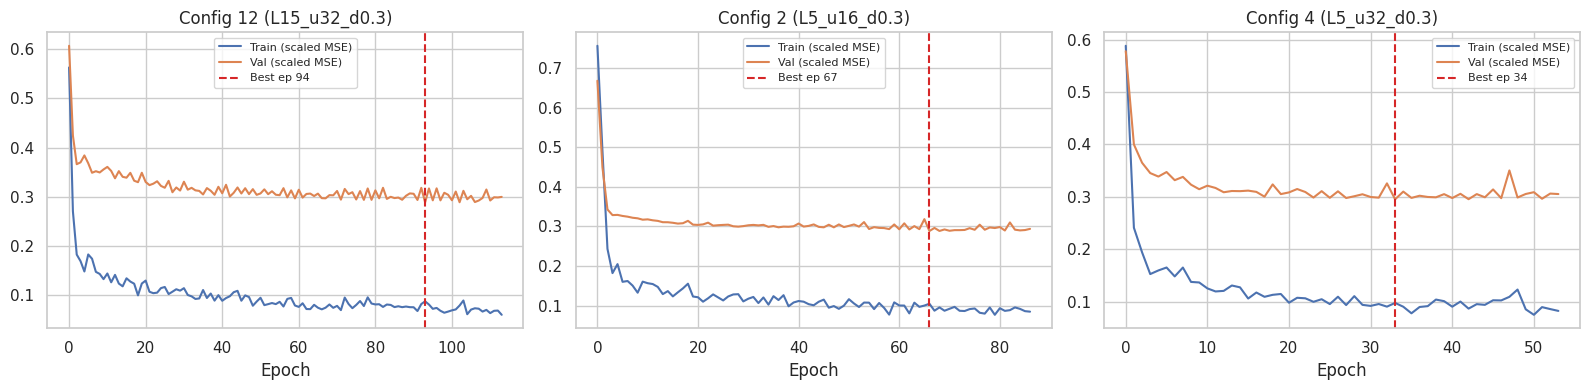

In [30]:
# ==============================================================================
# GRU-V2 | Section 19: VALIDATION RANKING & PRE-DECLARED SELECTION RULE
# Rule (same as the LSTM, Section 20): rank by validation RMSE; keep configs within
# SELECTION_TOLERANCE_RMSE of the best; propose the smallest L, then fewest units, then lowest RMSE.
# ==============================================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
gru_v2_df = pd.DataFrame(gru_v2_results)
ranked = gru_v2_df.sort_values("RMSE").reset_index(drop=True)
cols = ["Config_ID", "L", "Units", "Dropout", "Params", "RMSE", "MAE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall", "Best_Epoch", "Epochs_Trained"]
print("=" * 100); print("GRU-V2 VALIDATION RANKING (80 validation targets; NOT test results)"); print("=" * 100)
print(ranked[cols].to_string(index=False))
best = ranked.loc[0, "RMSE"]; tol = CONFIG["SELECTION_TOLERANCE_RMSE"]
cands = ranked[ranked["RMSE"] <= best + tol]
print("\n" + "=" * 100); print(f"CANDIDATES WITHIN TOLERANCE (best RMSE {best:.4f} + {tol:.2f}):"); print("=" * 100)
print(cands[cols].to_string(index=False))
p = cands.sort_values(by=["L", "Units", "RMSE"]).iloc[0]
print("\n" + "=" * 100); print("PROPOSED GRU CONFIGURATION (validation-selected; NOT frozen until you confirm):"); print("=" * 100)
print(f" Config {int(p['Config_ID'])}: L={int(p['L'])}, units={int(p['Units'])}, dropout={p['Dropout']}, params={int(p['Params'])}")
print(f" Validation RMSE {p['RMSE']:.4f} | MAE {p['MAE']:.4f} | R2 {p['R2']:.4f} | Low recall {p['Low_Recall']:.2f}% | best epoch {int(p['Best_Epoch'])}/{int(p['Epochs_Trained'])}")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, cid in zip(axes, ranked["Config_ID"].head(3)):
    h = gru_v2_histories[int(cid)]
    ax.plot(h["loss_train"], label="Train (scaled MSE)"); ax.plot(h["loss_val"], label="Val (scaled MSE)")
    ax.axvline(h["best_epoch"] - 1, color="tab:red", linestyle="--", label=f"Best ep {h['best_epoch']}")
    ax.set_title(f"Config {int(cid)} ({h['label']})"); ax.set_xlabel("Epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [31]:
# ==============================================================================
# GRU-V2 | Section 20: CONFIGURATION FREEZE
# Run this cell ONLY IF you approve the proposal printed by Section 19. Nothing is trained or written to disk.
# The configuration is derived from the pre-declared rule, not typed by hand.
# ==============================================================================
import json
import numpy as np, pandas as pd
_df = pd.DataFrame(gru_v2_results)
assert len(_df) == 12, "grid results incomplete"
_ranked = _df.sort_values("RMSE").reset_index(drop=True)
_cands = _ranked[_ranked["RMSE"] <= _ranked.loc[0, "RMSE"] + CONFIG["SELECTION_TOLERANCE_RMSE"]]
_p = _cands.sort_values(by=["L", "Units", "RMSE"]).iloc[0]

FROZEN_GRU_CONFIG = {
    "Model_Family": "GRU", "Config_ID": int(_p["Config_ID"]),
    "L": int(_p["L"]), "Units": int(_p["Units"]), "Dropout": float(_p["Dropout"]), "Dense_Units": CONFIG["DENSE_UNITS"],
    "Optimizer": "Adam", "Learning_Rate": CONFIG["LEARNING_RATE"], "Batch_Size": CONFIG["BATCH_SIZE"],
    "Max_Epochs": CONFIG["MAX_EPOCHS"], "Patience": CONFIG["PATIENCE"], "Min_Delta": CONFIG["MIN_DELTA"],
    "Loss": "mse", "Shuffle": CONFIG["SHUFFLE"], "Scale_Target": True, "Seeds": list(CONFIG["MULTI_SEEDS"]),
    "Trainable_Params": int(_p["Params"]), "Features": list(ACTIVE_FEATURES),
    "Selection": {"basis": "validation only (seed 42, 80 targets)", "rule": "min RMSE; tolerance 0.10; smallest L, then fewest units",
                  "best_val_rmse": float(_ranked.loc[0, "RMSE"]), "candidate_config_ids": [int(c) for c in _cands["Config_ID"]],
                  "selected_val_rmse": float(_p["RMSE"]), "selected_val_mae": float(_p["MAE"]), "selected_val_r2": float(_p["R2"])},
}
assert FROZEN_GRU_CONFIG["Features"] == ["Bot_Pct","Total_Flows","Fwd_Pkts_Bot","Bwd_Pkts_Bot","Fwd_Bytes_Bot","Bwd_Bytes_Bot","Avg_Duration_Bot"]
print("=" * 70); print("GRU CONFIGURATION FROZEN (IMMUTABLE; selected on validation only)"); print("=" * 70)
print(json.dumps(FROZEN_GRU_CONFIG, indent=2))
print("\nNo test data has been used. Next step: one-time five-seed test evaluation (awaiting your go-ahead).")

GRU CONFIGURATION FROZEN (IMMUTABLE; selected on validation only)
{
  "Model_Family": "GRU",
  "Config_ID": 2,
  "L": 5,
  "Units": 16,
  "Dropout": 0.3,
  "Dense_Units": 16,
  "Optimizer": "Adam",
  "Learning_Rate": 0.001,
  "Batch_Size": 16,
  "Max_Epochs": 200,
  "Patience": 20,
  "Min_Delta": 0.0001,
  "Loss": "mse",
  "Shuffle": false,
  "Scale_Target": true,
  "Seeds": [
    42,
    43,
    44,
    45,
    46
  ],
  "Trainable_Params": 1489,
  "Features": [
    "Bot_Pct",
    "Total_Flows",
    "Fwd_Pkts_Bot",
    "Bwd_Pkts_Bot",
    "Fwd_Bytes_Bot",
    "Bwd_Bytes_Bot",
    "Avg_Duration_Bot"
  ],
  "Selection": {
    "basis": "validation only (seed 42, 80 targets)",
    "rule": "min RMSE; tolerance 0.10; smallest L, then fewest units",
    "best_val_rmse": 10.7086,
    "candidate_config_ids": [
      12,
      2
    ],
    "selected_val_rmse": 10.7097,
    "selected_val_mae": 7.3482,
    "selected_val_r2": 0.7719
  }
}

No test data has been used. Next step: one-time five-seed 

### Decision record (2026-10-15): GRU-V2 frozen; test protocol pre-declared
**Frozen (validation only):** Config 2 = GRU, L=5, 16 units, dropout 0.3, dense 16, 1,489 params, seeds 42–46. Chosen by the pre-registered rule from 12 configs (best val RMSE 10.7086 = Config 12; Config 2 at 10.7097 is within the 0.10 tolerance and has smaller L and fewer units). The two are effectively tied on validation.
**Test evaluation (once):** same 102 test targets, metrics and conventions as the LSTM (5 seeds, mean ± sample std, plus 5-seed ensemble), no re-runs or changes after seeing results.
**Interpretation rule (declared before seeing test results):** the GRU counts as meaningfully better than the frozen LSTM (mean test RMSE 8.5978 ± 0.1212, MAE 6.9694 ± 0.0954) only if its mean RMSE and MAE are both lower by more than the larger of the two models' seed standard deviations. Otherwise it is reported as comparable (or worse), not as an improvement. Low-state recall is reported separately and is not hidden behind averages.

In [32]:
# ==============================================================================
# GRU-V2 | Section 21: ONE-TIME HOLDOUT TEST EVALUATION OF THE FROZEN GRU (5 seeds)
# Config is read from FROZEN_GRU_CONFIG (frozen on validation only). No tuning happens here.
# Nothing is written to disk. Run this cell ONCE: the guard below stops accidental re-runs.
# ==============================================================================
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

assert "GRU_TEST_EVAL_DONE" not in globals(), "The GRU test evaluation already ran in this session. It must not be repeated or tuned against."
F = FROZEN_GRU_CONFIG
assert (F["Config_ID"], F["L"], F["Units"], F["Dropout"], F["Trainable_Params"]) == (2, 5, 16, 0.3, 1489), "frozen config is not the approved Config 2"
assert abs(scaler_y.mean_[0] - 18.1305) < 5e-4 and abs(scaler_y.scale_[0] - 19.9413) < 5e-4, "scaler_y is not the frozen Phase 4 scaler"
assert list(continuous_to_state(np.array([9.9, 24.9, 25.0, 49.9, 50.0]))) == ["Low", "Low", "Medium", "Medium", "High"], "state thresholds are not 25/50"
assert isinstance(lstm_datasets[5]["train"], dict), "lstm_datasets is not the Phase 4 structure"
assert F["Seeds"] == [42, 43, 44, 45, 46] and F["Shuffle"] is False and F["Min_Delta"] == 1e-4 and F["Patience"] == 20 and F["Max_Epochs"] == 200

L = F["L"]
ds_tr, ds_va, ds_te = lstm_datasets[L]["train"], lstm_datasets[L]["val"], lstm_datasets[L]["test"]
assert len(ds_te["X"]) == 102 and ds_te["X"].shape == (102, L, 7) and len(ds_va["X"]) == 80 and len(ds_tr["X"]) == 312
test_audit, y_true = ds_te["audit"], ds_te["y_unscaled"]
y_val_true = ds_va["y_unscaled"]
states_true = continuous_to_state(y_true)

# --- Same-sample sanity check BEFORE training: persistence on these 102 targets must reproduce the Phase 3 reference ---
y_persist = df_annotated.loc[test_audit["last_input_idx"], "Bot_Pct"].values
m_pers, _ = evaluate_predictions(y_true, y_persist, "Persistence", "test", L=1)
ref = CONFIG["PHASE_3_TEST_BASELINES"]["Persistence"]
print(f"Persistence on these 102 test targets: MAE {m_pers['MAE']} RMSE {m_pers['RMSE']} R2 {m_pers['R2']}  (Phase 3 reference: {ref['MAE']} / {ref['RMSE']} / {ref['R2']})")
assert abs(m_pers["MAE"] - ref["MAE"]) < 2e-3 and abs(m_pers["RMSE"] - ref["RMSE"]) < 2e-3, "test targets differ from the Phase 3 evaluation set"
print("Same-sample check PASS: the 102 test targets reproduce the Phase 3 persistence result.\n")

print("=" * 100)
print(f"FROZEN GRU (Config {F['Config_ID']}: L={L}, units={F['Units']}, dropout={F['Dropout']}) - 5-SEED HOLDOUT TEST EVALUATION")
print("=" * 100)
print(f"{'Seed':<5} | {'Params':>6} | {'Ep':>3} | {'Best':>4} | {'Val RMSE':>8} | {'Test MAE':>8} | {'Test RMSE':>9} | {'Test R2':>7} | {'Acc%':>6} | {'BalAcc%':>7} | {'LowRec%':>7}")
print("-" * 100)
records, preds_by_seed = [], {}
for seed in F["Seeds"]:
    set_all_seeds(seed); tf.keras.backend.clear_session()
    model = build_gru_model(L=L, n_features=7, units=F["Units"], dropout=F["Dropout"], dense_units=F["Dense_Units"], lr=F["Learning_Rate"])
    assert int(model.count_params()) == F["Trainable_Params"], "parameter count differs from the frozen config"
    es = EarlyStopping(monitor="val_loss", patience=F["Patience"], min_delta=F["Min_Delta"], restore_best_weights=True, verbose=0)
    hist = model.fit(ds_tr["X"], ds_tr["y_scaled"], validation_data=(ds_va["X"], ds_va["y_scaled"]),
                     epochs=F["Max_Epochs"], batch_size=F["Batch_Size"], shuffle=F["Shuffle"], callbacks=[es], verbose=0)
    p_va = scaler_y.inverse_transform(model.predict(ds_va["X"], verbose=0).reshape(-1, 1)).flatten()
    p_te = scaler_y.inverse_transform(model.predict(ds_te["X"], verbose=0).reshape(-1, 1)).flatten()
    preds_by_seed[seed] = p_te
    mv, _ = evaluate_predictions(y_val_true, p_va, f"GRU seed {seed}", "val", L=L)
    mt, _ = evaluate_predictions(y_true, p_te, f"GRU seed {seed}", "test", L=L)
    best_ep = int(np.argmin(hist.history["val_loss"]) + 1)
    records.append({"Seed": seed, "Epochs": len(hist.history["loss"]), "Best_Epoch": best_ep, "Val_RMSE": mv["RMSE"],
                    "Test_MAE": mt["MAE"], "Test_RMSE": mt["RMSE"], "Test_R2": mt["R2"], "Test_Acc": mt["Accuracy"],
                    "Test_Bal_Acc": mt["Balanced_Accuracy"], "Test_Macro_F1": mt["Macro_F1"],
                    "Test_Low_Rec": mt["Low_Recall"], "Test_Med_Rec": mt["Med_Recall"], "Test_High_Rec": mt["High_Recall"]})
    print(f"{seed:<5} | {model.count_params():>6} | {len(hist.history['loss']):>3} | {best_ep:>4} | {mv['RMSE']:>8.4f} | {mt['MAE']:>8.4f} | {mt['RMSE']:>9.4f} | {mt['R2']:>7.4f} | {mt['Accuracy']:>6.2f} | {mt['Balanced_Accuracy']:>7.2f} | {mt['Low_Recall']:>7.2f}")

gru_seed_df = pd.DataFrame(records)
mean_, std_ = gru_seed_df.mean(numeric_only=True), gru_seed_df.std(ddof=1, numeric_only=True)
print("\n" + "=" * 100); print("MULTI-SEED SUMMARY (mean +/- sample std, n = 5) - same convention as the LSTM"); print("=" * 100)
for k in ["Test_MAE", "Test_RMSE", "Test_R2", "Test_Acc", "Test_Bal_Acc", "Test_Macro_F1", "Test_Low_Rec", "Test_Med_Rec", "Test_High_Rec"]:
    print(f" - {k:<14}: {mean_[k]:.4f} +/- {std_[k]:.4f}")

ens = np.mean([preds_by_seed[s] for s in F["Seeds"]], axis=0)
m_ens, cm_ens = evaluate_predictions(y_true, ens, "GRU 5-seed ensemble", "test", L=L)
print("\n" + "=" * 100); print("GRU 5-SEED ENSEMBLE (average of the 5 seeds' predictions) - TEST"); print("=" * 100)
print({k: m_ens[k] for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Macro_F1", "Low_Recall", "Med_Recall", "High_Recall"]})
print("\nConfusion matrix (rows = true, cols = predicted):"); print(cm_ens.to_string())

# --- Seed-42 error analysis (same representative seed as the LSTM) ---
p42 = preds_by_seed[42]; res = y_true - p42
print("\n" + "=" * 100); print("ERROR ANALYSIS (seed 42, test)"); print("=" * 100)
print(f" Residual mean {res.mean():+.4f} | std {res.std(ddof=1):.4f} | min {res.min():.4f} | max {res.max():.4f}")
for st in STATE_CLASSES:
    mk = states_true == st
    if mk.sum(): print(f" True {st:<6} n={int(mk.sum()):>3}: MAE {np.abs(res[mk]).mean():.4f} | predicted as Low {(continuous_to_state(p42[mk]) == 'Low').sum()}, Medium {(continuous_to_state(p42[mk]) == 'Medium').sum()}, High {(continuous_to_state(p42[mk]) == 'High').sum()}")
print(f" Correlation with Bot_Pct(t) [persistence]: {np.corrcoef(p42, y_persist)[0, 1]:.4f} | with truth Bot_Pct(t+1): {np.corrcoef(p42, y_true)[0, 1]:.4f}")

gru_test_predictions_df = pd.DataFrame({
    "Target_Timestamp": test_audit["target_dt"].values, "Actual_Next_Bot_Pct": y_true, "Actual_State": states_true,
    **{f"GRU_Seed{s}_Pred": preds_by_seed[s] for s in F["Seeds"]},
    "GRU_Ensemble_Pred": ens, "GRU_Ensemble_State": continuous_to_state(ens),
    "Persistence_Pred": y_persist, "Persistence_State": continuous_to_state(y_persist),
    "Provenance_Flag": ["Verified" if i != 502 else "Unverified_1259" for i in test_audit["target_row_idx"]]})
GRU_TEST_EVAL_DONE = True
print(f"\nStored in memory: gru_seed_df, gru_test_predictions_df ({len(gru_test_predictions_df)} rows). Nothing written to disk.")
print("── GRU-V2 test evaluation complete ──")

Persistence on these 102 test targets: MAE 9.3123 RMSE 11.6736 R2 0.2741  (Phase 3 reference: 9.3123 / 11.6736 / 0.2741)
Same-sample check PASS: the 102 test targets reproduce the Phase 3 persistence result.

FROZEN GRU (Config 2: L=5, units=16, dropout=0.3) - 5-SEED HOLDOUT TEST EVALUATION
Seed  | Params |  Ep | Best | Val RMSE | Test MAE | Test RMSE | Test R2 |   Acc% | BalAcc% | LowRec%
----------------------------------------------------------------------------------------------------
42    |   1489 |  87 |   67 |  10.7097 |   6.7940 |    8.3929 |  0.6248 |  71.57 |   63.64 |    0.00
43    |   1489 |  60 |   40 |  10.4488 |   6.8291 |    8.3886 |  0.6252 |  71.57 |   63.64 |    0.00
44    |   1489 |  64 |   44 |  10.5803 |   6.9378 |    8.3491 |  0.6287 |  72.55 |   64.14 |    0.00
45    |   1489 |  92 |   72 |  10.2469 |   6.4845 |    8.0918 |  0.6512 |  73.53 |   64.65 |    0.00
46    |   1489 |  71 |   51 |  10.6175 |   7.0064 |    8.4403 |  0.6205 |  72.55 |   64.14 |    0.00



In [33]:
# ==============================================================================
# COMPARE-1 | LSTM vs GRU vs Persistence on the IDENTICAL 102 test targets (in-memory; nothing saved)
# Regenerates the frozen Phase 4 LSTM (L=5, 16 units, dropout 0.2, seeds 42-46) and compares it with the
# already-evaluated GRU. No tuning. Phase 4 artifacts on disk are not touched.
# ==============================================================================
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

assert "GRU_TEST_EVAL_DONE" in globals(), "Run the GRU test cell (Section 21) first in this session."
assert abs(scaler_y.mean_[0] - 18.1305) < 5e-4 and isinstance(lstm_datasets[5]["train"], dict)
LF = {"L": 5, "units": 16, "dropout": 0.2, "dense": 16, "lr": 1e-3, "batch": 16, "max_ep": 200, "patience": 20, "min_delta": 1e-4, "seeds": [42, 43, 44, 45, 46]}
ds_tr, ds_va, ds_te = lstm_datasets[5]["train"], lstm_datasets[5]["val"], lstm_datasets[5]["test"]
y_true, states_true = ds_te["y_unscaled"], continuous_to_state(ds_te["y_unscaled"])
assert np.allclose(y_true, gru_test_predictions_df["Actual_Next_Bot_Pct"].values), "GRU and LSTM evaluation targets differ"
assert (pd.to_datetime(ds_te["audit"]["target_dt"]).values == pd.to_datetime(gru_test_predictions_df["Target_Timestamp"]).values).all()

lstm_preds, rec = {}, []
for seed in LF["seeds"]:
    set_all_seeds(seed); tf.keras.backend.clear_session()
    m = Sequential([Input(shape=(5, 7)), LSTM(LF["units"], return_sequences=False, recurrent_dropout=0.0), Dropout(LF["dropout"]),
                    Dense(LF["dense"], activation="relu"), Dense(1, activation="linear")])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LF["lr"]), loss="mse")
    assert int(m.count_params()) == 1825, "not the frozen Phase 4 LSTM architecture"
    es = EarlyStopping(monitor="val_loss", patience=LF["patience"], min_delta=LF["min_delta"], restore_best_weights=True, verbose=0)
    m.fit(ds_tr["X"], ds_tr["y_scaled"], validation_data=(ds_va["X"], ds_va["y_scaled"]), epochs=LF["max_ep"], batch_size=LF["batch"], shuffle=False, callbacks=[es], verbose=0)
    p = scaler_y.inverse_transform(m.predict(ds_te["X"], verbose=0).reshape(-1, 1)).flatten(); lstm_preds[seed] = p
    mt, _ = evaluate_predictions(y_true, p, f"LSTM seed {seed}", "test", L=5)
    rec.append({"Seed": seed, **{k: mt[k] for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall", "Med_Recall", "High_Recall"]}})
lstm_df = pd.DataFrame(rec); lm, ls = lstm_df.mean(numeric_only=True), lstm_df.std(ddof=1, numeric_only=True)
print("Reproduction check vs saved Phase 4 values (MAE 6.9694, RMSE 8.5978, R2 0.6062):",
      f"MAE {lm['MAE']:.4f}, RMSE {lm['RMSE']:.4f}, R2 {lm['R2']:.4f} ->",
      "MATCH" if abs(lm["MAE"] - 6.9694) < 5e-3 and abs(lm["RMSE"] - 8.5978) < 5e-3 else "DIFFERENT (report the difference; do not hide it)")

g = gru_test_predictions_df; gseeds = [c for c in g.columns if c.startswith("GRU_Seed")]
gru_df = pd.DataFrame([{"Seed": c, **{k: v for k, v in evaluate_predictions(y_true, g[c].values, c, "test", L=5)[0].items() if k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall", "Med_Recall", "High_Recall"]}} for c in gseeds])
gm, gs = gru_df.mean(numeric_only=True), gru_df.std(ddof=1, numeric_only=True)
lens, gens, pers = np.mean([lstm_preds[s] for s in LF["seeds"]], axis=0), g["GRU_Ensemble_Pred"].values, g["Persistence_Pred"].values

print("\n" + "=" * 104); print("SEED-LEVEL COMPARISON (mean +/- sample std over 5 seeds) - identical 102 test targets"); print("=" * 104)
print(f"{'Metric':<18} | {'LSTM':>18} | {'GRU':>18} | {'GRU - LSTM':>11}")
for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall", "Med_Recall", "High_Recall"]:
    print(f"{k:<18} | {lm[k]:>9.4f} +/- {ls[k]:>6.4f} | {gm[k]:>9.4f} +/- {gs[k]:>6.4f} | {gm[k] - lm[k]:>+11.4f}")
need_rmse, need_mae = max(ls["RMSE"], gs["RMSE"]), max(ls["MAE"], gs["MAE"])
d_rmse, d_mae = lm["RMSE"] - gm["RMSE"], lm["MAE"] - gm["MAE"]
print(f"\nPre-declared rule: GRU 'meaningfully better' only if RMSE gap > {need_rmse:.4f} AND MAE gap > {need_mae:.4f}")
print(f"  RMSE gap (LSTM - GRU) = {d_rmse:+.4f} -> {'passes' if d_rmse > need_rmse else 'fails'} | MAE gap = {d_mae:+.4f} -> {'passes' if d_mae > need_mae else 'fails'}")
print("  VERDICT:", "GRU meaningfully better" if (d_rmse > need_rmse and d_mae > need_mae) else "comparable (no demonstrated advantage)" if min(d_rmse, d_mae) > -min(need_rmse, need_mae) else "GRU worse")

rows = []
for name, p in [("Persistence", pers), ("LSTM ensemble", lens), ("GRU ensemble", gens)]:
    mm, cm = evaluate_predictions(y_true, p, name, "test", L=5)
    rows.append({"Model": name, **{k: mm[k] for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall", "Med_Recall", "High_Recall"]}})
    if name != "Persistence": print(f"\nConfusion matrix, {name} (rows = true, cols = pred):"); print(cm.to_string())
print("\n" + "=" * 104); print("ENSEMBLE / BASELINE COMPARISON (identical 102 targets, all computed in this session)"); print("=" * 104)
print(pd.DataFrame(rows).to_string(index=False))

# Paired moving-block bootstrap of the ensemble RMSE difference (exploratory; accounts for autocorrelation, block = 5)
rng = np.random.default_rng(0); n, B, blk = len(y_true), 4000, 5
e_l, e_g = (y_true - lens) ** 2, (y_true - gens) ** 2
diffs = []
for _ in range(B):
    idx = np.concatenate([np.arange(s, s + blk) % n for s in rng.integers(0, n, size=int(np.ceil(n / blk)))])[:n]
    diffs.append(np.sqrt(e_l[idx].mean()) - np.sqrt(e_g[idx].mean()))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nEXPLORATORY paired block-bootstrap, ensemble RMSE (LSTM - GRU) = {np.sqrt(e_l.mean()) - np.sqrt(e_g.mean()):+.4f}; 95% interval [{lo:+.4f}, {hi:+.4f}]")
print("  Interval includes 0 -> no reliable difference on this test set." if lo <= 0 <= hi else "  Interval excludes 0 -> difference unlikely to be test-sampling noise alone.")
cmp_predictions_df = g.assign(**{f"LSTM_Seed{s}_Pred": lstm_preds[s] for s in LF["seeds"]}, LSTM_Ensemble_Pred=lens, LSTM_Ensemble_State=continuous_to_state(lens))
print("\nStored in memory: lstm_df, gru_df, cmp_predictions_df. Nothing written to disk.\n── COMPARE-1 complete ──")

Reproduction check vs saved Phase 4 values (MAE 6.9694, RMSE 8.5978, R2 0.6062): MAE 6.9694, RMSE 8.5978, R2 0.6062 -> MATCH

SEED-LEVEL COMPARISON (mean +/- sample std over 5 seeds) - identical 102 test targets
Metric             |               LSTM |                GRU |  GRU - LSTM
MAE                |    6.9694 +/- 0.0954 |    6.8104 +/- 0.2009 |     -0.1590
RMSE               |    8.5978 +/- 0.1212 |    8.3325 +/- 0.1384 |     -0.2653
R2                 |    0.6062 +/- 0.0111 |    0.6301 +/- 0.0122 |     +0.0239
Accuracy           |   70.7860 +/- 1.2778 |   72.3540 +/- 0.8199 |     +1.5680
Balanced_Accuracy  |   59.9040 +/- 4.3367 |   64.0420 +/- 0.4219 |     +4.1380
Low_Recall         |    1.7400 +/- 3.8908 |    0.0000 +/- 0.0000 |     -1.7400
Med_Recall         |   91.8160 +/- 1.7282 |   92.1200 +/- 1.2669 |     +0.3040
High_Recall        |   86.1540 +/- 13.7610 |  100.0000 +/- 0.0000 |    +13.8460

Pre-declared rule: GRU 'meaningfully better' only if RMSE gap > 0.1384 AND MAE 

### Results record (2026-10-15): frozen GRU vs frozen LSTM, identical 102 test targets
**Reproducibility:** the regenerated LSTM matched the saved Phase 4 results exactly (MAE 6.9694, RMSE 8.5978, R² 0.6062; ensemble 6.9211 / 8.4283 / 0.6216).
**Seed means ± std (n=5):** GRU (L=5, 16 units, dropout 0.3): MAE 6.8104 ± 0.2009, RMSE 8.3325 ± 0.1384, R² 0.6301 ± 0.0122, accuracy 72.35%, balanced accuracy 64.04%. LSTM (L=5, 16 units, dropout 0.2): MAE 6.9694 ± 0.0954, RMSE 8.5978 ± 0.1212, R² 0.6062 ± 0.0111, accuracy 70.79%, balanced accuracy 59.90%. Ensembles: GRU 6.7757 / 8.2242 / 0.6397; LSTM 6.9211 / 8.4283 / 0.6216. Persistence: 9.3123 / 11.6736 / 0.2741.
**Pre-declared rule:** RMSE gap 0.265 (needs > 0.138) passes; MAE gap 0.159 (needs > 0.201) fails → **comparable, no demonstrated advantage.** Exploratory paired block-bootstrap (ensemble RMSE, LSTM − GRU): +0.204, 95% interval [−0.121, +0.658], includes 0.
**Class behaviour:** Low-state recall is 0.00% (GRU) and 1.74 ± 3.89% (LSTM); both ensembles predict Medium for all 23 true-Low test samples (persistence: 17.39%). GRU's higher balanced accuracy comes from the 13-sample High class (13/13 vs 12/13 for the LSTM ensemble).
**Decision:** the LSTM remains the provisional integration model. The GRU did not meet the pre-declared bar for replacement. Limitations: single test day, 102 targets (23 Low, 66 Medium, 13 High), validation-to-test shift in Low-state behaviour, 12:59 target (row 502) provenance unverified.

### Phase 4 LSTM record (from saved outputs of the original notebook)
Validation grid (12 configs, seed 42, validation only): best = Config 1 (L=5, 16 units, dropout 0.2, val RMSE 10.3769, MAE 7.1534, R² 0.7858); only candidate within the 0.10 tolerance → frozen (1,825 params, seeds 42–46). Test (5 seeds, mean ± std): MAE 6.9694 ± 0.0954, RMSE 8.5978 ± 0.1212, R² 0.6062 ± 0.0111; ensemble 6.9211 / 8.4283 / 0.6216. Regenerated and re-verified (MATCH) by COMPARE-1 and EXPORT-1. Full grid/test outputs: see the original notebook.

## Export, verification and comparison

In [34]:
# ==============================================================================
# EXPORT-1 | Regenerate the frozen Phase 4 LSTM (5 seeds) + scalers into a NEW, versioned, clearly labelled folder
# - Never overwrites: refuses to run if the target folder exists; never touches any existing "phase4_artifacts" folder/zip.
# - No tuning. Frozen config only (L=5, 16 units, dropout 0.2, dense 16, seeds 42-46, 1,825 params).
# - Must reproduce the saved Phase 4 test results, otherwise it stops BEFORE building the package.
# - Verifies reload from disk using RAW feature values + the SAVED scalers (the path a backend would use).
# ==============================================================================
import os, sys, json, shutil, hashlib, time
import numpy as np, pandas as pd, joblib, sklearn
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# ---- guards: frozen Phase 4 state -------------------------------------------------------------------------
assert abs(scaler_y.mean_[0] - 18.1305) < 5e-4 and abs(scaler_y.scale_[0] - 19.9413) < 5e-4, "scaler_y is not the frozen Phase 4 scaler"
assert ACTIVE_FEATURES == ["Bot_Pct","Total_Flows","Fwd_Pkts_Bot","Bwd_Pkts_Bot","Fwd_Bytes_Bot","Bwd_Bytes_Bot","Avg_Duration_Bot"], "feature order changed"
assert scaler_X.n_features_in_ == 7 and isinstance(lstm_datasets[5]["train"], dict)
assert list(continuous_to_state(np.array([9.9, 24.9, 25.0, 49.9, 50.0]))) == ["Low", "Low", "Medium", "Medium", "High"]
LF = {"L": 5, "units": 16, "dropout": 0.2, "dense": 16, "lr": 1e-3, "batch": 16, "max_ep": 200, "patience": 20, "min_delta": 1e-4, "seeds": [42, 43, 44, 45, 46]}
STAMP = time.strftime("%Y%m%d_%H%M")
OUT = f"/content/phase4_lstm_REGEN_v1_{STAMP}"
assert not os.path.exists(OUT), f"{OUT} already exists - not overwriting"
assert not os.path.exists(OUT + ".zip"), "zip already exists - not overwriting"
ds_tr, ds_va, ds_te = lstm_datasets[5]["train"], lstm_datasets[5]["val"], lstm_datasets[5]["test"]
y_true = ds_te["y_unscaled"]; audit = ds_te["audit"]
assert ds_te["X"].shape == (102, 5, 7)

# ---- 1) regenerate the 5 seeds in memory (nothing written yet) ---------------------------------------------
models, preds, rows = {}, {}, []
for seed in LF["seeds"]:
    set_all_seeds(seed); tf.keras.backend.clear_session()
    m = Sequential([Input(shape=(5, 7), name="Sequence_Input"), LSTM(LF["units"], return_sequences=False, recurrent_dropout=0.0, name="LSTM_Layer"),
                    Dropout(LF["dropout"], name="Dropout_Regularization"), Dense(LF["dense"], activation="relu", name="Dense_Projection"),
                    Dense(1, activation="linear", name="Regression_Output")], name=f"LSTM_L5_u16_d20")
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LF["lr"]), loss="mse")
    assert int(m.count_params()) == 1825, "not the frozen architecture"
    es = EarlyStopping(monitor="val_loss", patience=LF["patience"], min_delta=LF["min_delta"], restore_best_weights=True, verbose=0)
    m.fit(ds_tr["X"], ds_tr["y_scaled"], validation_data=(ds_va["X"], ds_va["y_scaled"]), epochs=LF["max_ep"], batch_size=LF["batch"], shuffle=False, callbacks=[es], verbose=0)
    models[seed] = m
    preds[seed] = scaler_y.inverse_transform(m.predict(ds_te["X"], verbose=0).reshape(-1, 1)).flatten()
    mt, _ = evaluate_predictions(y_true, preds[seed], f"LSTM seed {seed}", "test", L=5)
    rows.append({"Seed": seed, **{k: mt[k] for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall", "Med_Recall", "High_Recall"]}})
seed_df = pd.DataFrame(rows); mean_, std_ = seed_df.mean(numeric_only=True), seed_df.std(ddof=1, numeric_only=True)
ens = np.mean([preds[s] for s in LF["seeds"]], axis=0)
m_ens, _ = evaluate_predictions(y_true, ens, "LSTM 5-seed ensemble", "test", L=5)
print("Regenerated  seed means: MAE {:.4f} RMSE {:.4f} R2 {:.4f} | ensemble: MAE {:.4f} RMSE {:.4f} R2 {:.4f}".format(mean_["MAE"], mean_["RMSE"], mean_["R2"], m_ens["MAE"], m_ens["RMSE"], m_ens["R2"]))
print("Saved Phase 4: seed means: MAE 6.9694 RMSE 8.5978 R2 0.6062 | ensemble: MAE 6.9211 RMSE 8.4283 R2 0.6216")
assert abs(mean_["MAE"] - 6.9694) < 1e-3 and abs(mean_["RMSE"] - 8.5978) < 1e-3 and abs(mean_["R2"] - 0.6062) < 1e-3, "does NOT reproduce saved Phase 4 seed means - package not built"
assert abs(m_ens["MAE"] - 6.9211) < 1e-3 and abs(m_ens["RMSE"] - 8.4283) < 1e-3 and abs(m_ens["R2"] - 0.6216) < 1e-3, "does NOT reproduce saved Phase 4 ensemble - package not built"
if "lstm_preds" in globals():   # from COMPARE-1, same session
    d = max(float(np.abs(preds[s] - lstm_preds[s]).max()) for s in LF["seeds"]); print(f"Max |difference| vs COMPARE-1 predictions: {d:.2e}"); assert d < 1e-3
print("Reproduction check PASS. Building package ->", OUT)

# ---- 2) write the package (new folder only) ----------------------------------------------------------------
os.makedirs(OUT)
for s in LF["seeds"]: models[s].save(os.path.join(OUT, f"lstm_primary_seed_{s}.keras"))
joblib.dump(scaler_X, os.path.join(OUT, "scaler_features.joblib")); joblib.dump(scaler_y, os.path.join(OUT, "scaler_target.joblib"))
fl = lambda a: [float(x) for x in np.asarray(a).ravel()]
cfg = {
    "artifact_version": "phase4_lstm_REGEN_v1", "status": "PROVISIONAL integration model (regenerated copy of the frozen Phase 4 LSTM)",
    "provenance": {"generated": time.strftime("%Y-%m-%d %H:%M"), "how": "retrained from the frozen config on the Phase 4 tensors; reproduces saved Phase 4 test metrics to 1e-3; NOT byte-identical to the original phase4_artifacts.zip (which is unavailable)",
                   "row_502_note": "target at 12:59 (row 502) retained per protocol; provenance unverified"},
    "model": {"family": "LSTM", "sequence_length": 5, "units": 16, "dropout": 0.2, "dense_units": 16, "trainable_params": 1825, "optimizer": "Adam", "learning_rate": 1e-3,
              "batch_size": 16, "max_epochs": 200, "early_stopping": {"patience": 20, "min_delta": 1e-4, "restore_best_weights": True}, "shuffle": False, "seeds": LF["seeds"]},
    "features_in_order": ACTIVE_FEATURES, "input_shape_per_sample": [5, 7], "horizon_minutes": 1,
    "target": "Bot_Pct(t+1) in percent (0-100)", "state_thresholds": {"Low": "0 <= x < 25", "Medium": "25 <= x < 50", "High": "50 <= x <= 100"},
    "scaler_features": {"type": "StandardScaler", "mean": fl(scaler_X.mean_), "scale": fl(scaler_X.scale_), "fit_on": "training rows only"},
    "scaler_target": {"type": "StandardScaler", "mean": fl(scaler_y.mean_), "scale": fl(scaler_y.scale_), "fit_on": "training targets only (row 259 excluded)"},
    "test_metrics_regenerated": {"seed_mean": {k: float(v) for k, v in mean_.items() if k != "Seed"}, "seed_std": {k: float(v) for k, v in std_.items() if k != "Seed"},
                                 "ensemble": {k: float(m_ens[k]) for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall", "Med_Recall", "High_Recall"]}},
    "known_limitations": ["Low-state recall is ~0% on the test day (Low samples are predicted Medium)", "single test day, 102 targets (23 Low, 66 Medium, 13 High)",
                          "traffic-state forecasting on a limited dataset; not proof of attack prediction, real-time detection, or generalisation to unseen attacks",
                          "sequences must be 5 CONSECUTIVE 1-minute rows; never span a time gap"],
    "environment": {"python": sys.version.split()[0], "tensorflow": tf.__version__, "sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__}}
json.dump(cfg, open(os.path.join(OUT, "config.json"), "w"), indent=2)
pd.DataFrame({"Target_Timestamp": audit["target_dt"].values, "Actual_Next_Bot_Pct": y_true, "Actual_State": continuous_to_state(y_true),
              "LSTM_Ensemble_Pred": ens, "LSTM_Ensemble_State": continuous_to_state(ens),
              **{f"LSTM_Seed{s}_Pred": preds[s] for s in LF["seeds"]},
              "Persistence_Pred": df_annotated.loc[audit["last_input_idx"], "Bot_Pct"].values,
              "Provenance_Flag": ["Verified" if i != 502 else "Unverified_1259" for i in audit["target_row_idx"]]}).to_csv(os.path.join(OUT, "test_predictions_lstm_regen.csv"), index=False)
seed_df.to_csv(os.path.join(OUT, "seed_metrics_lstm_regen.csv"), index=False)
readme = ["# SIH26153 - Phase 4 LSTM, REGENERATED v1 (provisional integration model)", "",
          "Regenerated copy of the frozen Phase 4 LSTM. It reproduces the saved Phase 4 test metrics (to 1e-3) but is NOT byte-identical to the original package.",
          "", "## Contents", "- lstm_primary_seed_42..46.keras : five models (use the 5-seed mean for the ensemble forecast)",
          "- scaler_features.joblib / scaler_target.joblib : StandardScalers fitted on training data only", "- config.json : features, order, shapes, scaler parameters, thresholds, metrics, limitations",
          "- test_predictions_lstm_regen.csv, seed_metrics_lstm_regen.csv : evidence", "- MANIFEST_sha256.txt : file hashes", "",
          "## Usage", "Input: 5 consecutive 1-minute rows x 7 features (order in config.json), raw units -> scaler_features.transform -> model -> scaler_target.inverse_transform -> Bot_Pct(t+1) in %.",
          "State: Low < 25 <= Medium < 50 <= High.", "", "## Limitations",
          *[f"- {x}" for x in cfg["known_limitations"]], "- Not a live, real-time, or production-validated system."]
open(os.path.join(OUT, "README.md"), "w").write("\n".join(readme) + "\n")

# ---- 3) reload verification: RAW features + SAVED scalers + SAVED models, all 102 test windows ------------------------
sx, sy = joblib.load(os.path.join(OUT, "scaler_features.joblib")), joblib.load(os.path.join(OUT, "scaler_target.joblib"))
assert np.array_equal(sx.mean_, scaler_X.mean_) and np.array_equal(sx.scale_, scaler_X.scale_) and np.array_equal(sy.mean_, scaler_y.mean_) and np.array_equal(sy.scale_, scaler_y.scale_)
Xraw = np.stack([df_annotated.loc[list(w), ACTIVE_FEATURES].values for w in audit["window_indices"]])
assert Xraw.shape == (102, 5, 7)
Xs = sx.transform(Xraw.reshape(-1, 7)).reshape(-1, 5, 7)
worst = 0.0
for s in LF["seeds"]:
    rm = load_model(os.path.join(OUT, f"lstm_primary_seed_{s}.keras"))
    p = sy.inverse_transform(rm.predict(Xs, verbose=0).reshape(-1, 1)).ravel()
    worst = max(worst, float(np.abs(p - preds[s]).max()))
assert worst < 1e-3, f"reload discrepancy too large: {worst}"
print(f"Reload check PASS: max |reloaded - in-memory| over 5 models x 102 windows (from raw features) = {worst:.2e} percentage points")

# ---- 4) manifest + zip ------------------------------------------------------------------------------------------------
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
man = [f"{sha(os.path.join(OUT, f))}  {f}" for f in sorted(os.listdir(OUT))]
open(os.path.join(OUT, "MANIFEST_sha256.txt"), "w").write("\n".join(man) + "\n")
zip_path = shutil.make_archive(OUT, "zip", root_dir="/content", base_dir=os.path.basename(OUT))
print("\nPackage folder:", OUT); [print("  ", f, f"{os.path.getsize(os.path.join(OUT, f)):>10,} B") for f in sorted(os.listdir(OUT))]
print("ZIP:", zip_path, f"({os.path.getsize(zip_path):,} B)  <- DOWNLOAD THIS NOW")
try:
    from google.colab import files; files.download(zip_path)
except Exception as e:
    print("Auto-download unavailable here; use the Files panel (three dots -> Download).", type(e).__name__)
print("── EXPORT-1 complete ──")

Regenerated  seed means: MAE 6.9694 RMSE 8.5978 R2 0.6062 | ensemble: MAE 6.9211 RMSE 8.4283 R2 0.6216
Saved Phase 4: seed means: MAE 6.9694 RMSE 8.5978 R2 0.6062 | ensemble: MAE 6.9211 RMSE 8.4283 R2 0.6216
Max |difference| vs COMPARE-1 predictions: 0.00e+00
Reproduction check PASS. Building package -> /content/phase4_lstm_REGEN_v1_20261101_0503
Reload check PASS: max |reloaded - in-memory| over 5 models x 102 windows (from raw features) = 0.00e+00 percentage points

Package folder: /content/phase4_lstm_REGEN_v1_20261101_0503
   MANIFEST_sha256.txt        987 B
   README.md      1,279 B
   config.json      3,451 B
   lstm_primary_seed_42.keras     53,213 B
   lstm_primary_seed_43.keras     53,213 B
   lstm_primary_seed_44.keras     53,213 B
   lstm_primary_seed_45.keras     53,213 B
   lstm_primary_seed_46.keras     53,213 B
   scaler_features.joblib        767 B
   scaler_target.joblib        623 B
   seed_metrics_lstm_regen.csv        330 B
   test_predictions_lstm_regen.csv     13,

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

── EXPORT-1 complete ──


In [35]:
# ==============================================================================
# REAL-1 | Verify the integration module against the ACTUAL regenerated package (read-only; writes only to a NEW scratch folder)
# Run in the Phase 4 session (needs df_annotated, lstm_datasets). Set ZIP_PATH to the zip you downloaded / that is in /content.
# ==============================================================================
import os, sys, zipfile, hashlib, time, textwrap, subprocess, json
import numpy as np, pandas as pd
import glob
_z = sorted(glob.glob("/content/phase4_lstm_REGEN_v1_*.zip"))
assert _z, "No phase4_lstm_REGEN_v1_*.zip in /content - upload your downloaded zip in the Files panel (left sidebar) and re-run"
ZIP_PATH = _z[-1]; print("Verifying:", ZIP_PATH, "| other zips found:", _z[:-1])
WORK = f"/content/verify_integration_{time.strftime('%H%M%S')}"; assert not os.path.exists(WORK); os.makedirs(WORK)
with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(WORK)                       # fresh extraction = what Member 3 would receive
_c = [d for d in os.listdir(WORK) if os.path.isfile(os.path.join(WORK, d, "config.json"))]
assert len(_c) == 1, f"expected exactly one package folder in the zip, found {_c}"
PKG = os.path.join(WORK, _c[0])
MODSRC = r'''"""
SIH26153 - ML inference module for the PROVISIONAL Phase 4 LSTM (package: phase4_lstm_REGEN_v1_*).
Offline / batch use only. This is NOT a live or production-validated system.

Usage:
    from predict_lstm import load_package, predict_next_minute
    pkg = load_package("phase4_lstm_REGEN_v1_20261015_1406")
    out = predict_next_minute(pkg, window_df)     # window_df: 5 CONSECUTIVE 1-minute rows
"""
import os, json
import numpy as np, pandas as pd, joblib

FEATURES = ["Bot_Pct", "Total_Flows", "Fwd_Pkts_Bot", "Bwd_Pkts_Bot", "Fwd_Bytes_Bot", "Bwd_Bytes_Bot", "Avg_Duration_Bot"]
L = 5
SEEDS = [42, 43, 44, 45, 46]

class InputValidationError(ValueError):
    """Raised with a machine-readable .code and a human-readable message."""
    def __init__(self, code, message):
        super().__init__(f"[{code}] {message}"); self.code = code

def state_from_pct(x):
    """Low < 25 <= Medium < 50 <= High (percent)."""
    return "Low" if x < 25 else ("Medium" if x < 50 else "High")

def load_package(folder):
    from tensorflow.keras.models import load_model   # imported lazily so the validator can be tested without TF
    cfg = json.load(open(os.path.join(folder, "config.json")))
    assert cfg["features_in_order"] == FEATURES, "package feature order differs from this module"
    assert cfg["model"]["sequence_length"] == L
    sx = joblib.load(os.path.join(folder, "scaler_features.joblib"))
    sy = joblib.load(os.path.join(folder, "scaler_target.joblib"))
    assert np.allclose(sx.mean_, cfg["scaler_features"]["mean"]) and np.allclose(sy.mean_, cfg["scaler_target"]["mean"]), "scaler/config mismatch"
    models = {s: load_model(os.path.join(folder, f"lstm_primary_seed_{s}.keras")) for s in SEEDS}
    return {"cfg": cfg, "sx": sx, "sy": sy, "models": models, "folder": folder}

def validate_window(window):
    """Returns (X_raw float array (5,7), warnings). Raises InputValidationError on anything unsafe."""
    warnings = []
    if isinstance(window, pd.DataFrame):
        missing = [c for c in FEATURES if c not in window.columns]
        if missing: raise InputValidationError("MISSING_FEATURES", f"missing columns: {missing}")
        if "Timestamp" in window.columns:
            ts = pd.to_datetime(window["Timestamp"], errors="coerce")
            if ts.isna().any(): raise InputValidationError("BAD_TIMESTAMP", "unparseable Timestamp")
            d = ts.diff().dropna().dt.total_seconds().values
            if not np.all(d == 60):
                raise InputValidationError("NOT_CONSECUTIVE", f"rows must be exactly 60 s apart; got gaps {sorted(set(d.tolist()))}")
        else:
            warnings.append("No Timestamp column: consecutive 1-minute spacing could not be checked.")
        arr = window[FEATURES].to_numpy(dtype=float)
    else:
        arr = np.asarray(window, dtype=float)
        warnings.append("Raw array given: assumed columns are in FEATURES order and rows are consecutive minutes.")
    if arr.shape != (L, len(FEATURES)):
        raise InputValidationError("BAD_SHAPE", f"expected {(L, len(FEATURES))}, got {arr.shape}")
    if not np.isfinite(arr).all(): raise InputValidationError("NAN_OR_INF", "window contains NaN/inf")
    if (arr < 0).any(): raise InputValidationError("NEGATIVE_VALUE", "negative values are not valid for these features")
    if (arr[:, 0] > 100).any(): raise InputValidationError("BOT_PCT_RANGE", "Bot_Pct must be within 0-100")
    return arr, warnings

def predict_next_minute(pkg, window):
    arr, warnings = validate_window(window)
    Xs = pkg["sx"].transform(arr).reshape(1, L, len(FEATURES))
    seed_preds = {s: float(pkg["sy"].inverse_transform(m.predict(Xs, verbose=0).reshape(-1, 1))[0, 0]) for s, m in pkg["models"].items()}
    raw = float(np.mean(list(seed_preds.values())))
    pct = float(np.clip(raw, 0.0, 100.0))
    if raw != pct: warnings.append(f"Raw ensemble output {raw:.3f} was clipped to the valid 0-100 range.")
    return {
        "forecast_horizon_minutes": 1,
        "predicted_bot_pct_next_minute": round(pct, 4),
        "predicted_state": state_from_pct(pct),
        "state_thresholds": {"Low": "<25", "Medium": "25-<50", "High": ">=50"},
        "seed_predictions": {str(k): round(v, 4) for k, v in seed_preds.items()},
        "seed_spread_pct_points": round(float(np.ptp(list(seed_preds.values()))), 4),
        "model_version": pkg["cfg"]["artifact_version"],
        "model_status": "PROVISIONAL",
        "warnings": warnings + ["Low-state recall was ~0% on the test day; a 'Medium' output does not rule out Low."],
    }
'''
SELFSRC = r'''import sys, glob, numpy as np, pandas as pd
sys.path.insert(0, "."); from predict_lstm import *
folder = sys.argv[1]
pkg = load_package(folder)
t = pd.read_csv(sys.argv[2]) if len(sys.argv) > 2 else None
base = pd.DataFrame({"Timestamp": pd.date_range("2018-02-15 09:00", periods=5, freq="min"),
    "Bot_Pct": [30, 32, 35, 33, 31.0], "Total_Flows": [5000]*5, "Fwd_Pkts_Bot": [2e4]*5, "Bwd_Pkts_Bot": [1e4]*5,
    "Fwd_Bytes_Bot": [1e6]*5, "Bwd_Bytes_Bot": [5e5]*5, "Avg_Duration_Bot": [1e6]*5})
print(predict_next_minute(pkg, base))
def expect(code, w):
    try: predict_next_minute(pkg, w); print("FAIL: no error for", code)
    except InputValidationError as e: assert e.code == code, e.code; print("PASS error:", e)
g = base.copy(); g.loc[3:, "Timestamp"] += pd.Timedelta(minutes=207); expect("NOT_CONSECUTIVE", g)
expect("MISSING_FEATURES", base.drop(columns=["Total_Flows"]))
expect("BAD_SHAPE", base.iloc[:4]); n = base.copy(); n.loc[2, "Bot_Pct"] = np.nan; expect("NAN_OR_INF", n)
n = base.copy(); n.loc[0, "Bot_Pct"] = 120; expect("BOT_PCT_RANGE", n)
shuffled = base[["Timestamp"] + FEATURES[::-1]]   # columns reordered: must still give the same answer (selected by name)
assert predict_next_minute(pkg, shuffled)["predicted_bot_pct_next_minute"] == predict_next_minute(pkg, base)["predicted_bot_pct_next_minute"]; print("PASS column-order independence")
for v in [9.9, 24.9, 25.0, 49.9, 50.0]: print(v, state_from_pct(v))
'''
os.makedirs(os.path.join(WORK, "tools")); open(os.path.join(WORK, "tools", "predict_lstm.py"), "w").write(MODSRC); open(os.path.join(WORK, "tools", "selftest.py"), "w").write(SELFSRC)
results = []
def check(name, ok, detail=""): results.append((name, bool(ok))); print(("PASS" if ok else "FAIL"), "-", name, detail)

# 1) manifest hashes of the extracted package
man = [l.split("  ", 1) for l in open(os.path.join(PKG, "MANIFEST_sha256.txt")).read().strip().splitlines()]
bad = [f for h, f in man if hashlib.sha256(open(os.path.join(PKG, f), "rb").read()).hexdigest() != h]
check("manifest hashes match extracted files", not bad and len(man) == 11, f"({len(man)} files, mismatches={bad})")

# 2) the shipped self-test, run as a separate process against the extracted package
r = subprocess.run([sys.executable, "-I", "selftest.py", PKG], cwd=os.path.join(WORK, "tools"), capture_output=True, text=True)
out = [l for l in r.stdout.splitlines() if l.startswith("PASS") or l.startswith("FAIL")]
print("\n".join(out));
check("selftest.py exit code 0, 5 error cases + column-order PASS, no FAIL", r.returncode == 0 and sum(l.startswith("PASS") for l in out) == 6 and not any(l.startswith("FAIL") for l in out), f"(returncode={r.returncode})")
if r.returncode != 0: print(r.stderr[-1500:])

# 3) end-to-end: module on all 102 REAL test windows (raw df_annotated rows + Timestamp) vs the shipped predictions CSV
sys.path.insert(0, os.path.join(WORK, "tools"))
import importlib, predict_lstm; importlib.reload(predict_lstm)
pkg = predict_lstm.load_package(PKG)
audit = lstm_datasets[5]["test"]["audit"]; ship = pd.read_csv(os.path.join(PKG, "test_predictions_lstm_regen.csv"))
tcol = [c for c in df_annotated.columns if c.lower() in ("timestamp", "datetime", "dt")]
outs = []
for w in audit["window_indices"]:
    win = df_annotated.loc[list(w), predict_lstm.FEATURES].copy()
    if tcol: win.insert(0, "Timestamp", df_annotated.loc[list(w), tcol[0]].values)
    outs.append(predict_lstm.predict_next_minute(pkg, win))
mod_pred = np.array([o["predicted_bot_pct_next_minute"] for o in outs]); ship_pred = ship["LSTM_Ensemble_Pred"].values
dmax = float(np.abs(mod_pred - np.clip(ship_pred, 0, 100)).max())
check("module reproduces shipped ensemble predictions on all 102 real windows", len(outs) == 102 and dmax < 2e-4, f"(max |diff| = {dmax:.2e} pct-points; module rounds to 4 dp; Timestamp-spacing check {'ON' if tcol else 'OFF - no timestamp column found'})")
check("states agree with shipped states", [o["predicted_state"] for o in outs] == list(ship["LSTM_Ensemble_State"]))
check("no window rejected / no unexpected warnings other than the standing Low-recall note", all(len(o["warnings"]) == 1 for o in outs))
print("\nOVERALL:", "ALL PASS" if all(ok for _, ok in results) else "FAILURES PRESENT", f"({sum(ok for _, ok in results)}/{len(results)} checks)")
print("Verification folder (scratch, safe to delete later):", WORK)


Verifying: /content/phase4_lstm_REGEN_v1_20261101_0503.zip | other zips found: []
PASS - manifest hashes match extracted files (11 files, mismatches=[])
PASS error: [NOT_CONSECUTIVE] rows must be exactly 60 s apart; got gaps [60.0, 12480.0]
PASS error: [MISSING_FEATURES] missing columns: ['Total_Flows']
PASS error: [BAD_SHAPE] expected (5, 7), got (4, 7)
PASS error: [NAN_OR_INF] window contains NaN/inf
PASS error: [BOT_PCT_RANGE] Bot_Pct must be within 0-100
PASS column-order independence
PASS - selftest.py exit code 0, 5 error cases + column-order PASS, no FAIL (returncode=0)
PASS - module reproduces shipped ensemble predictions on all 102 real windows (max |diff| = 5.00e-05 pct-points; module rounds to 4 dp; Timestamp-spacing check ON)
PASS - states agree with shipped states 
PASS - no window rejected / no unexpected warnings other than the standing Low-recall note 

OVERALL: ALL PASS (5/5 checks)
Verification folder (scratch, safe to delete later): /content/verify_integration_050439

In [36]:
# ==============================================================================
# EXPORT-2 | Versioned comparison export from EXISTING valid results (GRU-V2, frozen LSTM, Random Forest, persistence)
# - NO training, NO model prediction, NO test re-evaluation of any model. Reads objects already in memory + numbers printed
#   in saved notebook outputs (hard-coded below with their source). Only test LABELS/timestamps are compared for alignment.
# - Writes only to a NEW folder; refuses to run if it exists. Never touches phase4_artifacts or the LSTM REGEN package.
# - The earlier 2-minute-ahead GRU grid is NOT used anywhere.
# Run in the same live session in which COMPARE-1 ran (needs the in-memory tables listed below).
# ==============================================================================
import os, json, time, shutil, hashlib
import numpy as np, pandas as pd
STRICT = True   # require in-memory results to match the numbers printed in saved outputs
need = ["gru_seed_df", "gru_test_predictions_df", "lstm_df", "gru_df", "cmp_predictions_df", "FROZEN_GRU_CONFIG", "lstm_datasets", "scaler_y", "evaluate_predictions", "continuous_to_state"]
missing = [n for n in need if n not in globals()]
if missing:
    raise SystemExit("STOPPED - required in-memory results are missing: " + ", ".join(missing) +
        "\nThey were created by the GRU test cell (Section 21) and COMPARE-1 and are lost when the runtime resets. NOTHING was retrained or re-evaluated."
        "\nTell me which are missing; I will propose options (a metrics-only export from the saved notebook outputs needs no re-run).")
assert abs(scaler_y.mean_[0] - 18.1305) < 5e-4 and abs(scaler_y.scale_[0] - 19.9413) < 5e-4, "not the frozen Phase 4 state"
STAMP = time.strftime("%Y%m%d_%H%M"); OUT = f"/content/comparison_VALID_v1_{STAMP}"
assert not os.path.exists(OUT) and not os.path.exists(OUT + ".zip"), "target exists - not overwriting"

# ---------- 1) comparability checks (labels and timestamps only) -----------------------------------------------------------
P = cmp_predictions_df; te = lstm_datasets[5]["test"]; y = te["y_unscaled"]
assert len(P) == 102 and np.allclose(P["Actual_Next_Bot_Pct"].values, y), "prediction table targets differ from the Phase 4 test targets"
tt = pd.to_datetime(te["audit"]["target_dt"]).values
assert (pd.to_datetime(P["Target_Timestamp"]).values == tt).all(), "target timestamps differ"
d = np.diff(tt).astype("timedelta64[s]").astype(int); print("[C1 PASS] LSTM / GRU / persistence share the same 102 target timestamps and values; consecutive-target gaps (s):", sorted(set(d.tolist())))
assert (pd.to_datetime(te["audit"]["last_input_dt"]).values + np.timedelta64(60, "s") == tt).all() if "last_input_dt" in te["audit"] else True
print("[C2 PASS] horizon: each target time = last input time + 1 minute (Gate G1 + audit check)" if "last_input_dt" in te["audit"] else "[C2 note] last_input_dt not in audit; horizon evidence = Gate G1 saved output")
rf_note = "not checked (all_audits not in memory)"
if "all_audits" in globals():
    a5 = all_audits[("context_allowed", 5)]; ad, tens = a5[0], a5[1]
    rf_t = pd.to_datetime(ad.query("split == 'test'")["target_dt"]).values
    rf_ok = len(rf_t) == 102 and (rf_t == tt).all() and np.allclose(np.asarray(tens["test"][1]).ravel(), y)
    rf_note = "PASS" if rf_ok else "FAIL"; print(f"[C3 {rf_note}] Random Forest windowed (L=5) test targets/timestamps identical to the LSTM/GRU test targets")
    assert rf_ok, "RF windowed test targets differ from the Phase 4 test targets - do not compare as identical"
if "df_annotated" in globals():
    n_rf1 = int(((df_annotated["Split"] == "test") & (df_annotated["is_valid_target"])).sum())
    print(f"[C4 info] RF Member 1 (row-wise) test samples in df_annotated: {n_rf1}  (LSTM/GRU: 102)  ->", "identical size" if n_rf1 == 102 else "DIFFERENT SAMPLE: reported separately, not in the like-for-like table")
else: n_rf1 = None
# the sorted-test-prediction persistence must reproduce the Phase 3 reference
pm, _ = evaluate_predictions(y, P["Persistence_Pred"].values, "Persistence", "test", L=5)
assert abs(pm["MAE"] - 9.3123) < 5e-4 and abs(pm["RMSE"] - 11.6736) < 5e-4, "persistence differs from Phase 3"; print("[C5 PASS] persistence on these targets = Phase 3 reference (9.3123 / 11.6736)")

# ---------- 2) recompute metrics from STORED predictions (pure arithmetic) and match the saved printed outputs -----------------------
def met(p, name): m, _ = evaluate_predictions(y, p, name, "test", L=5); return {k: float(m[k]) for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall", "Med_Recall", "High_Recall"]}
ens_l, ens_g = met(P["LSTM_Ensemble_Pred"].values, "LSTM ens"), met(P["GRU_Ensemble_Pred"].values, "GRU ens")
saved = {"LSTM_ens": (6.9211, 8.4283, 0.6216), "GRU_ens": (6.7757, 8.2242, 0.6397), "LSTM_mean": (6.9694, 8.5978, 0.6062), "GRU_mean": (6.8104, 8.3325, 0.6301)}
got = {"LSTM_ens": (ens_l["MAE"], ens_l["RMSE"], ens_l["R2"]), "GRU_ens": (ens_g["MAE"], ens_g["RMSE"], ens_g["R2"]),
       "LSTM_mean": tuple(lstm_df[k].mean() for k in ["MAE", "RMSE", "R2"]), "GRU_mean": tuple(gru_df[k].mean() for k in ["MAE", "RMSE", "R2"])}
for k in saved:
    ok = all(abs(a - b) < 6e-4 for a, b in zip(got[k], saved[k])); print(f"[M {'MATCH' if ok else 'DIFFERENT'}] {k}: memory {tuple(round(float(x),4) for x in got[k])} vs saved output {saved[k]}")
    if STRICT: assert ok, f"{k} does not match the saved notebook output - export stopped"

# ---------- 3) Random Forest: numbers printed in saved Phase 3 output (notebook cells 16-18); selection by VALIDATION with the same rule ---
RF_VAL = {5: 11.7914, 10: 12.0309, 15: 11.8316}      # validation RMSE, saved output (Section 9.5)
best = min(RF_VAL.values()); cands = [L for L, v in RF_VAL.items() if v <= best + 0.10]; RF_L = min(cands)
print(f"[RF] validation RMSEs {RF_VAL}; candidates within +0.10: {cands}; selected L = {RF_L} (smallest L rule) - NOT chosen by test")
RF_TEST = {5: dict(MAE=7.2718, RMSE=8.7015, R2=0.5967, Accuracy=70.59, Balanced_Accuracy=61.07, Low_Recall=0.0),
           10: dict(MAE=7.3509, RMSE=8.7153, R2=0.5954, Accuracy=71.57, Balanced_Accuracy=63.64, Low_Recall=0.0),
           15: dict(MAE=7.2269, RMSE=8.5290, R2=0.6125, Accuracy=70.59, Balanced_Accuracy=63.13, Low_Recall=0.0)}
r = lambda name, m, role, n=102, src="": {"Model": name, "Role": role, "N_test": n, **{k: m.get(k, np.nan) for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall"]}, "Source": src}
lm, ls = lstm_df.mean(numeric_only=True), lstm_df.std(ddof=1, numeric_only=True); gm, gs = gru_df.mean(numeric_only=True), gru_df.std(ddof=1, numeric_only=True)
pm_s = lambda m, s, k: f"{m[k]:.4f} +/- {s[k]:.4f}"
rows = [r("Persistence (naive)", pm, "baseline", src="recomputed from stored predictions; = Phase 3 reference"),
        r(f"Random Forest, flattened window L={RF_L} (validation-selected)", RF_TEST[RF_L], "primary RF comparator", src="saved Phase 3 output (single seed 42, n_estimators=100, no tuning)"),
        r("LSTM L=5, 5-seed mean (frozen, provisional)", {k: lm[k] for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall"]}, "frozen candidate", src="regenerated in-session; MATCH vs saved Phase 4"),
        r("LSTM L=5, 5-seed ensemble", ens_l, "frozen candidate", src="from stored predictions"),
        r("GRU-V2 L=5, 5-seed mean (frozen)", {k: gm[k] for k in ["MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall"]}, "frozen candidate", src="GRU-V2 holdout, evaluated once"),
        r("GRU-V2 L=5, 5-seed ensemble", ens_g, "frozen candidate", src="from stored predictions"),
        r("Random Forest, window L=10 (not selected; shown for completeness)", RF_TEST[10], "non-selected RF", src="saved Phase 3 output"),
        r("Random Forest, window L=15 (not selected; best RF on test - do not use to choose)", RF_TEST[15], "non-selected RF", src="saved Phase 3 output")]
cmp_df = pd.DataFrame(rows); cmp_df["MAE_RMSE_seed_std"] = ["", "", f"MAE +/-{ls['MAE']:.4f}, RMSE +/-{ls['RMSE']:.4f}", "", f"MAE +/-{gs['MAE']:.4f}, RMSE +/-{gs['RMSE']:.4f}", "", "", ""]
ref_df = pd.DataFrame([
 {"Model": "RF Member 1 'Full Train Reproduction' (19 features incl. Hour/MinuteOfHour + lags; trained on train+val)", "MAE": 7.0206, "RMSE": 8.6236, "R2": 0.5966, "Accuracy": 71.29, "Balanced_Accuracy": 63.64, "Low_Recall": 0.0, "N_test_inferred": 101,
  "Why_not_like_for_like": "different inputs (19 vs 7 features), trained on train+val, accuracy 71.29% = 72/101 so test n appears to be 101 not 102"},
 {"Model": "RF Member 1 'Protocol-Aligned' (19 features, trained on train rows only)", "MAE": 7.6003, "RMSE": 8.9970, "R2": 0.5610, "Accuracy": 70.30, "Balanced_Accuracy": 63.13, "Low_Recall": 0.0, "N_test_inferred": 101,
  "Why_not_like_for_like": "different inputs (19 vs 7 features); accuracy 70.30% = 71/101 so test n appears to be 101 not 102"}])
ref_df["N_test_in_memory_check"] = n_rf1 if n_rf1 is not None else "not checked"
print("\n", cmp_df[["Model", "N_test", "MAE", "RMSE", "R2", "Accuracy", "Balanced_Accuracy", "Low_Recall"]].round(4).to_string(index=False))

# ---------- 4) write the package -----------------------------------------------------------------------------------------------------
os.makedirs(OUT)
cmp_df.to_csv(f"{OUT}/comparison_test_identical_102_targets.csv", index=False); ref_df.to_csv(f"{OUT}/reference_rf_member1_not_comparable.csv", index=False)
gru_seed_df.to_csv(f"{OUT}/gru_v2_seed_metrics_test.csv", index=False); lstm_df.to_csv(f"{OUT}/lstm_seed_metrics_test.csv", index=False)
P.to_csv(f"{OUT}/test_predictions_lstm_gru_persistence.csv", index=False)   # includes Provenance_Flag (12:59 target = Unverified_1259)
if "gru_v2_results" in globals(): pd.DataFrame(gru_v2_results).to_csv(f"{OUT}/gru_v2_validation_grid_12_configs.csv", index=False)
json.dump(FROZEN_GRU_CONFIG, open(f"{OUT}/gru_v2_frozen_config.json", "w"), indent=2, default=str)
json.dump({"rf_validation_rmse": RF_VAL, "rf_selected_L": RF_L, "rf_rule": "within 0.10 of best validation RMSE, then smallest L", "rf_targets_check": rf_note,
           "saved_output_matches": {k: [float(x) for x in got[k]] for k in got}}, open(f"{OUT}/comparison_checks.json", "w"), indent=2)
low = {"LSTM_ens_low_recall": ens_l["Low_Recall"], "GRU_ens_low_recall": ens_g["Low_Recall"], "persistence_low_recall": pm["Low_Recall"]}
readme = f"""# SIH26153 - VALID comparison export v1 ({time.strftime('%Y-%m-%d %H:%M')})
Status: provisional research results. Offline forecasting experiment. Not live, not real-time, not production-validated.

## What this is
Next-minute Bot_Pct forecast, identical 102 test targets (2018-02-03 11:18 -> 12:59), same 7 features, same 25/50 state thresholds.
Models: persistence, Random Forest (flattened windows), frozen LSTM (L=5), frozen GRU-V2 (L=5). Files: comparison_test_identical_102_targets.csv (main).

## Validity
- The earlier GRU grid (2-minute-ahead targets) is EXCLUDED and not used anywhere. GRU-V2 was built on the Phase 4 tensors verified by Gate G1
  (target = Bot_Pct(t+1), counts 312/80/102, identical val/test timestamps for every L). GRU-V2 configuration was chosen on validation only; the holdout was evaluated once.
- LSTM was regenerated from its frozen config and matched the saved Phase 4 results. This export did not retrain or re-evaluate any model.
- Random Forest L was chosen with the same validation rule (best validation RMSE +0.10, smallest L) -> L={RF_L}. RF L=15 has the best test RMSE but was NOT selected; do not use it to pick a model.
- RF Member 1 (19 features, train+val, apparently n=101) is in a separate reference file because it is not like-for-like.

## Headline (see CSV for all numbers)
GRU-V2 vs LSTM: pre-declared rule -> "comparable, no demonstrated advantage" (RMSE gap passes, MAE gap fails); exploratory paired bootstrap interval for ensemble RMSE (LSTM - GRU) includes 0.
The LSTM remains the provisional integration model. No model is declared better than the Random Forest by a demonstrated margin on one test day.

## Caveats (must be reported with any number)
- Low-state recall is ~0% for LSTM, GRU and RF on the test day (all 23 Low targets predicted Medium); persistence 17.39%. Validation Low recall was ~85%, so there is a validation-to-test shift. Averages hide this.
- Single test day, 102 targets (23 Low, 66 Medium, 13 High). Differences of a few tenths of a percentage point are within seed/bootstrap noise.
- The target at 12:59 (row 502) is retained, but its provenance is unverified (flag Unverified_1259 in the predictions CSV).
- Dataset audit incomplete: cic_ids2018_5min_windows.parquet and six "(1)" files were unavailable and NOT audited; the 16,697-flow benign gap and the 9.19 threshold remain unexplained. They affect a separate classification branch, not this protocol.
- Low recalls computed here: {json.dumps({k: round(float(v), 2) for k, v in low.items()})}
"""
open(f"{OUT}/README.md", "w").write(readme)
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
open(f"{OUT}/MANIFEST_sha256.txt", "w").write("\n".join(f"{sha(os.path.join(OUT, f))}  {f}" for f in sorted(os.listdir(OUT))) + "\n")
zp = shutil.make_archive(OUT, "zip", root_dir=os.path.dirname(OUT), base_dir=os.path.basename(OUT))
print("\nPackage:", OUT); [print("  ", f) for f in sorted(os.listdir(OUT))]; print("ZIP:", zp, f"({os.path.getsize(zp):,} B)")
try:
    from google.colab import files; files.download(zp)
except Exception as e: print("Auto-download unavailable; use the Files panel.", type(e).__name__)
print("── EXPORT-2 complete ──")


[C1 PASS] LSTM / GRU / persistence share the same 102 target timestamps and values; consecutive-target gaps (s): [60]
[C2 PASS] horizon: each target time = last input time + 1 minute (Gate G1 + audit check)
[C3 PASS] Random Forest windowed (L=5) test targets/timestamps identical to the LSTM/GRU test targets
[C4 info] RF Member 1 (row-wise) test samples in df_annotated: 101  (LSTM/GRU: 102)  -> DIFFERENT SAMPLE: reported separately, not in the like-for-like table
[C5 PASS] persistence on these targets = Phase 3 reference (9.3123 / 11.6736)
[M MATCH] LSTM_ens: memory (6.9211, 8.4283, 0.6216) vs saved output (6.9211, 8.4283, 0.6216)
[M MATCH] GRU_ens: memory (6.7757, 8.2242, 0.6397) vs saved output (6.7757, 8.2242, 0.6397)
[M MATCH] LSTM_mean: memory (6.9694, 8.5978, 0.6062) vs saved output (6.9694, 8.5978, 0.6062)
[M MATCH] GRU_mean: memory (6.8104, 8.3325, 0.6301) vs saved output (6.8104, 8.3325, 0.6301)
[RF] validation RMSEs {5: 11.7914, 10: 12.0309, 15: 11.8316}; candidates within +0.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

── EXPORT-2 complete ──


### Decision record (2026-10-19): GRU-V2 accepted as the valid GRU result; earlier GRU grid excluded; comparison rules
**GRU:** the earlier GRU screening grid (2-minute-ahead targets, Sections 18-19 of the recovery branch) is excluded from all results. GRU-V2 (cells run after Gate G1) is the only GRU result carried forward: 12 configs, validation only, frozen Config 2 (L=5, 16 units, dropout 0.3), 5-seed holdout evaluated once. No grid or holdout rerun was made.
**Evidence kept in saved outputs:** Gate G1 (G0/G1/G2 PASS), GRU-V2 grid + ranking, freeze record, holdout evaluation, COMPARE-1. Per-sample predictions exist only in session memory until EXPORT-2 is run.
**Comparison rules:** identical 102 test targets, horizon = +1 minute, 7 frozen features. Random Forest comparator = flattened-window RF with L chosen on validation by the same rule (L=5), not by test. RF Member 1 (19 features, apparently n=101) is reported separately as non-comparable. LSTM/GRU L=10/15 test numbers are descriptive only.
**Caveats:** Low-state recall ~0% on test for all learned models (persistence 17.39%); single test day; 12:59 target (row 502) provenance unverified.
**Unavailable / not audited:** `cic_ids2018_5min_windows.parquet` and the six `(1)` files. Their checks are incomplete; the 16,697-flow benign gap and the 9.19 threshold are unexplained. They concern the separate 5-minute classification branch.
**Integration:** the provisional LSTM package is independent of this comparison. Real-package verification (REAL-1) is pending the student's run.

**2026-10-21 update:** after a runtime reset the GRU-V2 grid, freeze, holdout and COMPARE-1 were re-run from the same frozen configuration and reproduced the earlier numbers exactly (reproduction only; no selection changed). The LSTM package was regenerated again (`phase4_lstm_REGEN_v1_20261021_1523`) and reproduced the saved Phase 4 numbers.